#### Notebook 02 — Home Location Inference

Objective: Estimate each eligible subscriber's most likely residential location using recurring nighttime network activity, compare alternative inference methods, and evaluate the results against the synthetic ground truth where available.

This notebook answers the question: Where is this subscriber most likely to live?

#### Section 1 — Setup and data loading

In [267]:
# Cell 1: Imports

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Cell 2: Project paths and configuration

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"
REPORT_PATH = PROJECT_ROOT / "reports"

DATA_FILE = RAW_PATH / "MPD_sample_synthetic_ken_3000subs_full.csv"

NOTEBOOK02_OUTPUT = PROCESSED_PATH / "notebook_02"

NOTEBOOK02_OUTPUT.mkdir(parents=True, exist_ok=True)
REPORT_PATH.mkdir(parents=True, exist_ok=True)

# Inference configuration
NIGHT_START_HOUR = 20
NIGHT_END_HOUR = 6

MIN_DISTINCT_NIGHTS = 3

# Initial cell-coordinate quality threshold.
# This is a configurable starting assumption, not a validated universal threshold.
MAX_CELL_COORDINATE_SPREAD_M = 100

# Initial confidence thresholds.
HIGH_CONFIDENCE_THRESHOLD = 0.60
MEDIUM_CONFIDENCE_THRESHOLD = 0.35

# DBSCAN parameters
DBSCAN_EPS_KM = 1.0
DBSCAN_MIN_SAMPLES = 2

EARTH_RADIUS_KM = 6371.0088

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_FILE)
print("Output directory:", NOTEBOOK02_OUTPUT)

Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Dataset: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/raw/MPD_sample_synthetic_ken_3000subs_full.csv
Output directory: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_02


In [268]:
# 3: Load the full dataset

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}"
    )

df_full = pd.read_csv(
    DATA_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string",
        "latitude": "float64",
        "longitude": "float64",
        "data_type": "category",
        "service": "category",
        "location_target": "category",
        "location_place": "category",
        "profile": "category",
        "record_profile": "category",
        "movement_profile": "category"
    },
    low_memory=False
)

print("Dataset shape:", df_full.shape)

print("\nColumns:")
print(df_full.columns.tolist())

display(df_full.head())

Dataset shape: (1072608, 16)

Columns:
['msisdn', 'datetime', 'cell_id', 'latitude', 'longitude', 'data_type', 'service', 'location_target', 'location_place', 'movement_dist', 'movement_speed', 'is_robot', 'profile', 'tourist', 'record_profile', 'movement_profile']


,msisdn,datetime,cell_id,latitude,longitude,data_type,service,location_target,location_place,movement_dist,movement_speed,is_robot,profile,tourist,record_profile,movement_profile
0,subscribers_00323,2026-02-01 01:23:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,0,neutral,False,very_high,short
1,subscribers_00323,2026-02-01 03:55:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,0,neutral,False,very_high,short
2,subscribers_00323,2026-02-01 06:53:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,0,neutral,False,very_high,short
3,subscribers_00323,2026-02-01 07:52:00,33597,-1.2674,36.9147,CDR,2G,home,home,0.0000,0.0000,0,neutral,False,very_high,short
4,subscribers_00323,2026-02-01 09:07:00,31239,-1.2712,36.8996,CDR,2G,other,other,1.7280,0.3840,0,neutral,False,very_high,short


In [269]:
# 4: Convert data types

df_full["msisdn"] = df_full["msisdn"].astype("string").str.strip()
df_full["cell_id"] = df_full["cell_id"].astype("string").str.strip()

df_full["datetime"] = pd.to_datetime(
    df_full["datetime"],
    errors="coerce"
)

for col in ["latitude", "longitude", "movement_dist", "movement_speed"]:
    if col in df_full.columns:
        df_full[col] = pd.to_numeric(
            df_full[col],
            errors="coerce"
        )

# Convert synthetic Boolean labels safely.
def convert_to_boolean(series):
    mapped = (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map({
            "1": True,
            "0": False,
            "true": True,
            "false": False,
            "yes": True,
            "no": False
        })
    )

    return mapped.astype("boolean")


df_full["tourist"] = convert_to_boolean(df_full["tourist"])
df_full["is_robot"] = convert_to_boolean(df_full["is_robot"])

categorical_columns = [
    "data_type",
    "service",
    "location_target",
    "location_place",
    "profile",
    "record_profile",
    "movement_profile"
]

for col in categorical_columns:
    if col in df_full.columns:
        df_full[col] = df_full[col].astype("category")


print(df_full.dtypes)

msisdn                      string
datetime            datetime64[us]
cell_id                     string
latitude                   float64
longitude                  float64
data_type                 category
service                   category
location_target           category
location_place            category
movement_dist              float64
movement_speed             float64
is_robot                   boolean
profile                   category
tourist                    boolean
record_profile            category
movement_profile          category
dtype: object


In [270]:
# 5: Initial data validation

print("Dataset shape:", df_full.shape)

print("\nUnique subscribers:")
print(df_full["msisdn"].nunique())

print("\nUnique cell IDs:")
print(df_full["cell_id"].nunique())

print("\nDate range:")
print("Start:", df_full["datetime"].min())
print("End:", df_full["datetime"].max())

print("\nMissing values:")
display(
    df_full.isna().sum().to_frame("missing_values")
)

print("\nDuplicate rows:")
print(df_full.duplicated().sum())

Dataset shape: (1072608, 16)

Unique subscribers:
3000

Unique cell IDs:
35956

Date range:
Start: 2026-02-01 00:02:00
End: 2026-02-28 23:59:00

Missing values:


,missing_values
msisdn,0
datetime,0
cell_id,0
latitude,0
longitude,0
data_type,0
service,0
location_target,0
location_place,0
movement_dist,0



Duplicate rows:
0


In [271]:
# 6: Validate essential columns and coordinates

required_columns = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude",
    "tourist",
    "is_robot",
    "location_target",
    "location_place"
]

missing_columns = [
    col for col in required_columns
    if col not in df_full.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# Check invalid coordinates
invalid_coordinates = (
    ~df_full["latitude"].between(-90, 90)
    | ~df_full["longitude"].between(-180, 180)
)

print("Rows with invalid coordinates:", invalid_coordinates.sum())

# Remove rows with missing essential fields or invalid coordinates.
# Keep df_full unchanged as the original loaded dataset.
df_analysis = df_full.dropna(
    subset=[
        "msisdn",
        "datetime",
        "cell_id",
        "latitude",
        "longitude"
    ]
).loc[~invalid_coordinates].copy()

print("Original rows:", len(df_full))
print("Rows after essential-field validation:", len(df_analysis))
print("Rows removed:", len(df_full) - len(df_analysis))

Rows with invalid coordinates: 0
Original rows: 1072608
Rows after essential-field validation: 1072608
Rows removed: 0


#### Section 2 - Subscriber classification and filtering

This section uses the synthetic tourist and is_robot flags to identify subscribers who should not be included in ordinary residential inference.

In [272]:
# 7: Subscriber-level classification

subscriber_flags = (
    df_analysis.groupby("msisdn", observed=True)
    .agg(
        tourist_values=("tourist", "nunique"),
        robot_values=("is_robot", "nunique"),
        tourist_flag=("tourist", "first"),
        robot_flag=("is_robot", "first"),
        total_events=("datetime", "size"),
        active_days=(
            "datetime",
            lambda x: x.dt.normalize().nunique()
        ),
        first_seen=("datetime", "min"),
        last_seen=("datetime", "max"),
        unique_cells=("cell_id", "nunique")
    )
    .reset_index()
)


def classify_subscriber(row):

    # Missing or inconsistent labels
    if (
        pd.isna(row["tourist_flag"])
        or pd.isna(row["robot_flag"])
        or row["tourist_values"] != 1
        or row["robot_values"] != 1
    ):
        return "unknown"

    # Both flags are true
    if row["tourist_flag"] and row["robot_flag"]:
        return "tourist_and_robot"

    if row["tourist_flag"]:
        return "tourist"

    if row["robot_flag"]:
        return "automated"

    return "ordinary"


subscriber_flags["subscriber_type"] = (
    subscriber_flags.apply(
        classify_subscriber,
        axis=1
    )
)

display(
    subscriber_flags["subscriber_type"]
    .value_counts(dropna=False)
    .to_frame("subscriber_count")
)

,subscriber_count
subscriber_type,
ordinary,2813
tourist,174
automated,13


,subscriber_type,subscriber_count,percentage
0,ordinary,2813,93.7667
1,tourist,174,5.8000
2,automated,13,0.4333


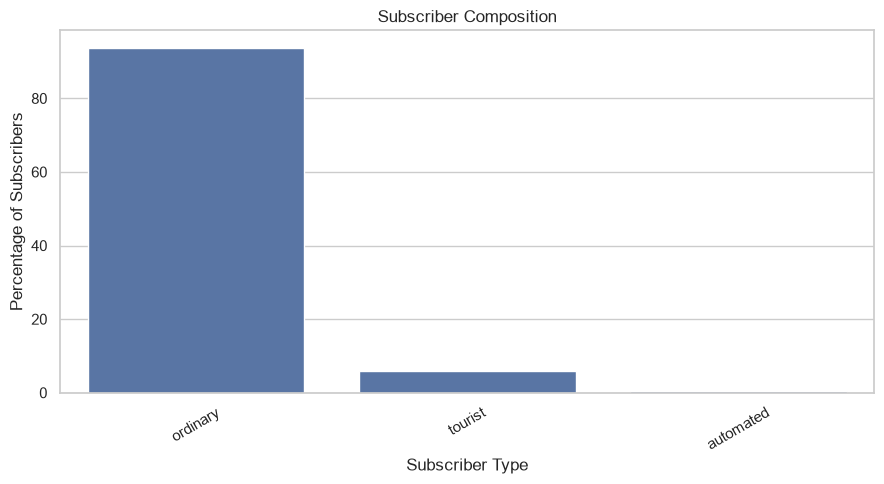

In [273]:
# 8: Subscriber classification percentages

subscriber_composition = (
    subscriber_flags["subscriber_type"]
    .value_counts(dropna=False)
    .rename_axis("subscriber_type")
    .reset_index(name="subscriber_count")
)

subscriber_composition["percentage"] = (
    subscriber_composition["subscriber_count"]
    / subscriber_composition["subscriber_count"].sum()
    * 100
)

display(subscriber_composition)


plt.figure(figsize=(9, 5))

sns.barplot(
    data=subscriber_composition,
    x="subscriber_type",
    y="percentage"
)

plt.title("Subscriber Composition")
plt.xlabel("Subscriber Type")
plt.ylabel("Percentage of Subscribers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [274]:
# 9: Tourist activity profile

tourist_ids = subscriber_flags.loc[
    subscriber_flags["subscriber_type"] == "tourist",
    "msisdn"
].unique()

tourist_events = df_analysis[
    df_analysis["msisdn"].isin(tourist_ids)
].copy()


tourist_profile = (
    tourist_events.groupby("msisdn", observed=True)
    .agg(
        total_events=("datetime", "size"),
        active_days=(
            "datetime",
            lambda x: x.dt.normalize().nunique()
        ),
        first_seen=("datetime", "min"),
        last_seen=("datetime", "max"),
        unique_cells=("cell_id", "nunique")
    )
    .reset_index()
)

tourist_profile["observed_span_days"] = (
    tourist_profile["last_seen"].dt.normalize()
    - tourist_profile["first_seen"].dt.normalize()
).dt.days + 1

tourist_profile["days_without_events_within_span"] = (
    tourist_profile["observed_span_days"]
    - tourist_profile["active_days"]
)

display(tourist_profile.head())

print("Tourist subscribers:", len(tourist_profile))

,msisdn,total_events,active_days,first_seen,last_seen,unique_cells,observed_span_days,days_without_events_within_span
0,subscribers_00047,20,3,2026-02-21 09:27:00,2026-02-23 14:40:00,14,3,0
1,subscribers_00060,2,1,2026-02-21 14:22:00,2026-02-21 22:42:00,2,1,0
2,subscribers_00063,5,3,2026-02-17 18:53:00,2026-02-19 20:17:00,1,3,0
3,subscribers_00069,27,5,2026-02-11 06:26:00,2026-02-15 21:18:00,15,5,0
4,subscribers_00103,119,4,2026-02-15 01:35:00,2026-02-18 23:26:00,54,4,0


Tourist subscribers: 174


### Interpretation: Tourist Subscriber Activity Profile

The analysis identifies **174 tourist subscribers** and examines their activity patterns, observation periods, and geographic diversity.

**Key observations:**

1. **Tourist population:** A total of 174 subscribers were classified as tourists in the dataset.
2. **Short observation periods:** The examples show observation windows ranging from 1 to 5 days, consistent with temporary subscriber presence.
3. **Variable activity levels:** Total events range from 2 to 119 among the five displayed subscribers, indicating differences in network usage.
4. **Geographic diversity:** Unique cell counts vary considerably, from 1 to 54, suggesting different levels of movement during visitors' stays.
5. **Continuous activity:** All five displayed subscribers have zero days without events within their observed spans, meaning they generated at least one event on every day between their first and last observations.

### Summary of Findings

The analysis identifies 174 tourist subscribers exhibiting temporary network presence and varying levels of activity and geographic mobility.

**Implication for the project:** Tourist subscribers should be excluded from resident population and home-location inference analyses because their temporary presence could distort estimates of habitual residential locations and population distribution.

In [275]:
# 10: Automated device profile

robot_ids = subscriber_flags.loc[
    subscriber_flags["subscriber_type"] == "automated",
    "msisdn"
].unique()

# Include overlapping tourist_and_robot subscribers in the automated
# device removal list as well.
overlapping_robot_ids = subscriber_flags.loc[
    subscriber_flags["subscriber_type"] == "tourist_and_robot",
    "msisdn"
].unique()

all_robot_ids = np.concatenate([
    robot_ids,
    overlapping_robot_ids
])

all_robot_ids = pd.Index(all_robot_ids).unique()


# Extract automated events for profiling.
robot_events = df_analysis[
    df_analysis["msisdn"].isin(all_robot_ids)
].copy()


robot_profile = (
    robot_events.groupby("msisdn", observed=True)
    .agg(
        total_events=("datetime", "size"),
        active_days=(
            "datetime",
            lambda x: x.dt.normalize().nunique()
        ),
        unique_cells=("cell_id", "nunique"),
        first_seen=("datetime", "min"),
        last_seen=("datetime", "max")
    )
    .reset_index()
)


# Count unique coordinate pairs, not just unique latitude values.
robot_coordinate_counts = (
    robot_events[
        ["msisdn", "latitude", "longitude"]
    ]
    .drop_duplicates()
    .groupby("msisdn", observed=True)
    .size()
    .rename("unique_coordinate_pairs")
    .reset_index()
)

robot_profile = robot_profile.merge(
    robot_coordinate_counts,
    on="msisdn",
    how="left"
)

display(robot_profile.head())

print("Automated subscribers, including overlaps:", len(all_robot_ids))
print("Automated-device events:", len(robot_events))

,msisdn,total_events,active_days,unique_cells,first_seen,last_seen,unique_coordinate_pairs
0,subscribers_00165,7317,28,1,2026-02-01 00:47:00,2026-02-28 23:52:00,1
1,subscribers_00237,7389,28,1,2026-02-01 00:07:00,2026-02-28 23:55:00,1
2,subscribers_00258,7011,28,1,2026-02-01 01:14:00,2026-02-28 23:55:00,1
3,subscribers_00372,7296,28,1,2026-02-01 00:11:00,2026-02-28 23:31:00,1
4,subscribers_00629,7119,28,1,2026-02-01 00:13:00,2026-02-28 23:58:00,1


Automated subscribers, including overlaps: 13
Automated-device events: 94978


### Interpretation: Automated Device Activity Profile

The analysis identifies subscribers classified as automated devices and examines their network activity and geographic consistency.

**Key observations:**

1. **High event frequency:** Each displayed device generates approximately 6,900–7,500 events, significantly higher than typical individual subscriber activity.
2. **Consistent activity:** All displayed devices are active across all 28 days of February 2026.
3. **Single-cell connectivity:** Every displayed device connects through exactly one unique cell ID.
4. **Stable geographic location:** Each device has only one unique latitude/longitude coordinate pair, indicating no observed geographic movement.
5. **Continuous presence:** Devices remain observable throughout the entire study period, from February 1 to February 28.

### Summary of Findings

The displayed automated devices exhibit highly consistent, repetitive network activity, with high event volumes and no geographic movement.

**Implication for the project:** These devices are likely fixed network equipment, IoT devices, or machine-generated connections rather than ordinary mobile subscribers. They should be excluded from human mobility analysis, residential inference, and population displacement estimation to avoid distorting results.

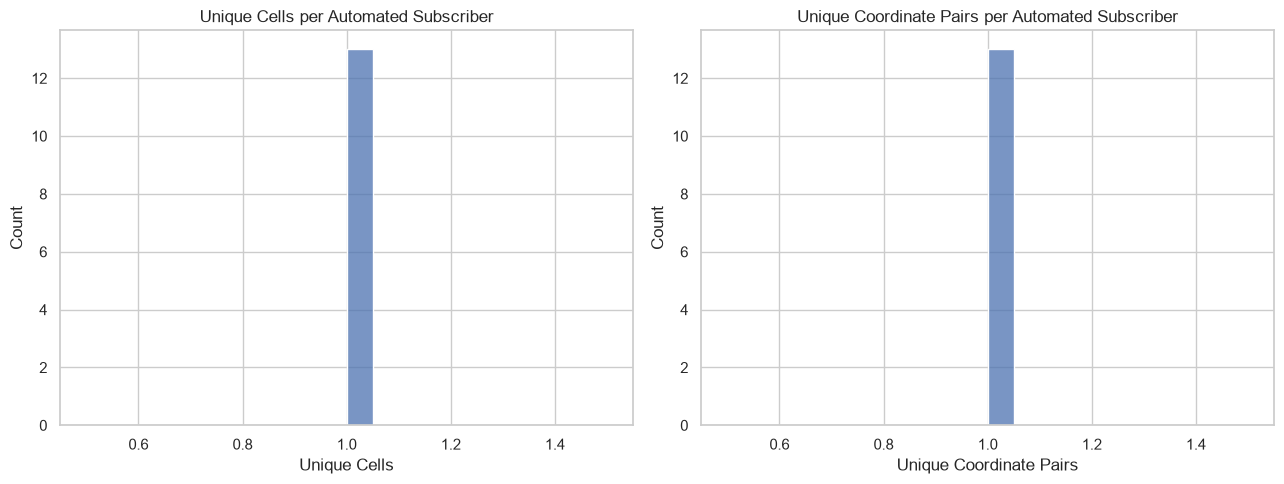

In [276]:
# 11: Inspect automated device behaviour

if not robot_profile.empty:

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    sns.histplot(
        data=robot_profile,
        x="unique_cells",
        bins=20,
        ax=axes[0]
    )

    axes[0].set_title("Unique Cells per Automated Subscriber")
    axes[0].set_xlabel("Unique Cells")

    sns.histplot(
        data=robot_profile,
        x="unique_coordinate_pairs",
        bins=20,
        ax=axes[1]
    )

    axes[1].set_title("Unique Coordinate Pairs per Automated Subscriber")
    axes[1].set_xlabel("Unique Coordinate Pairs")

    plt.tight_layout()
    plt.show()

else:
    print("No automated subscribers found.")

In [277]:
# 12: Explicitly remove automated devices

df_no_automated = df_analysis[
    ~df_analysis["msisdn"].isin(all_robot_ids)
].copy()


print("Rows before automated-device removal:", len(df_analysis))
print("Rows after automated-device removal:", len(df_no_automated))
print("Automated events removed:", len(df_analysis) - len(df_no_automated))

print(
    "Automated subscribers remaining:",
    df_no_automated["msisdn"].isin(all_robot_ids).sum()
)

assert not df_no_automated["msisdn"].isin(all_robot_ids).any(), (
    "ERROR: Automated-device records remain in df_no_automated."
)

print("Validation passed: automated-device records removed.")

Rows before automated-device removal: 1072608
Rows after automated-device removal: 977630
Automated events removed: 94978
Automated subscribers remaining: 0
Validation passed: automated-device records removed.


In [278]:
# 13: Remove tourists and unknown subscriber types
# The residential inference dataset should contain ordinary human subscribers only.

ordinary_ids = subscriber_flags.loc[
    subscriber_flags["subscriber_type"] == "ordinary",
    "msisdn"
].unique()


df_residential = df_no_automated[
    df_no_automated["msisdn"].isin(ordinary_ids)
].copy()


print("Original validated rows:", len(df_analysis))
print("After automated-device removal:", len(df_no_automated))
print("Final residential inference rows:", len(df_residential))

print("\nSubscriber counts:")
print("All validated subscribers:", df_analysis["msisdn"].nunique())
print("After automated removal:", df_no_automated["msisdn"].nunique())
print("Ordinary subscribers:", df_residential["msisdn"].nunique())


# Verify no tourist, automated or unknown subscribers remain.
remaining_types = subscriber_flags.loc[
    subscriber_flags["msisdn"].isin(
        df_residential["msisdn"].unique()
    ),
    "subscriber_type"
].value_counts()

display(remaining_types)

assert set(remaining_types.index) == {"ordinary"}
assert not df_residential["msisdn"].isin(all_robot_ids).any()

print("Validation passed: only ordinary subscribers remain.")

Original validated rows: 1072608
After automated-device removal: 977630
Final residential inference rows: 968858

Subscriber counts:
All validated subscribers: 3000
After automated removal: 2987
Ordinary subscribers: 2813


subscriber_type
ordinary    2813
Name: count, dtype: int64

Validation passed: only ordinary subscribers remain.


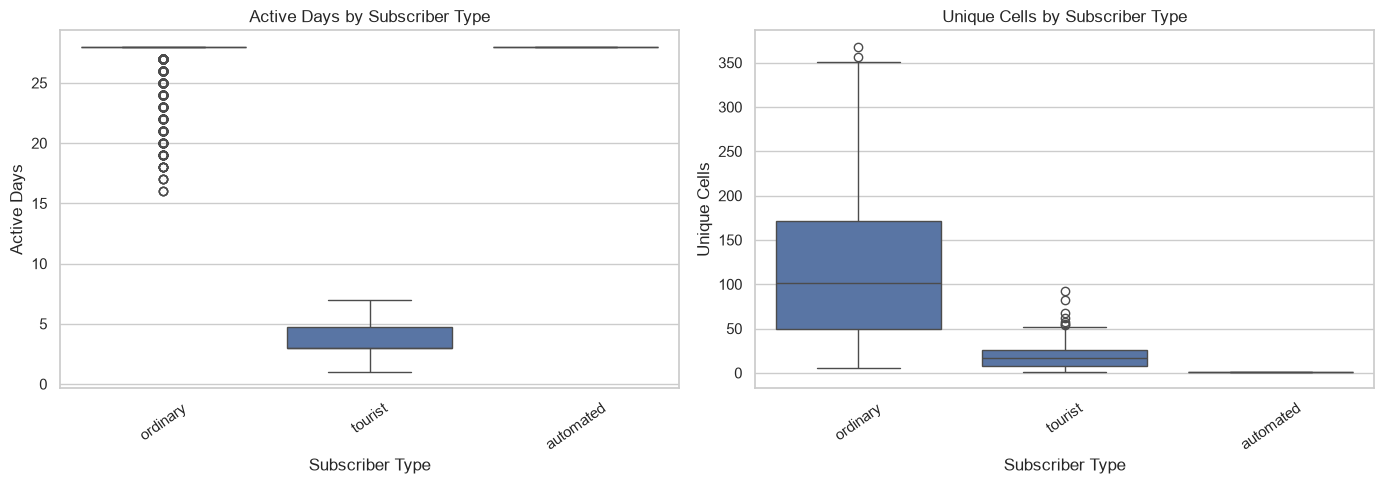

In [279]:
# 14: Compare activity across subscriber types

comparison_data = subscriber_flags[
    subscriber_flags["subscriber_type"].isin([
        "ordinary",
        "tourist",
        "automated",
        "tourist_and_robot",
        "unknown"
    ])
].copy()


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=comparison_data,
    x="subscriber_type",
    y="active_days",
    ax=axes[0]
)

axes[0].set_title("Active Days by Subscriber Type")
axes[0].set_xlabel("Subscriber Type")
axes[0].set_ylabel("Active Days")
axes[0].tick_params(axis="x", rotation=35)


sns.boxplot(
    data=comparison_data,
    x="subscriber_type",
    y="unique_cells",
    ax=axes[1]
)

axes[1].set_title("Unique Cells by Subscriber Type")
axes[1].set_xlabel("Subscriber Type")
axes[1].set_ylabel("Unique Cells")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

### Interpretation: Subscriber Activity by Type

**1. Active Days**
- **Ordinary subscribers:** Generally active throughout the 28-day observation period, although some have fewer active days.
- **Tourist subscribers:** Have significantly fewer active days, typically between 3 and 5 days, with a range of approximately 1–7 days.
- **Automated devices:** Consistently active across all 28 days.

**2. Geographic Diversity (Unique Cells)**
- **Ordinary subscribers:** Exhibit the highest geographic diversity, with a median of approximately 100 unique cells and substantial variation across subscribers.
- **Tourist subscribers:** Use considerably fewer cells, with a median of approximately 16, suggesting more limited geographic movement.
- **Automated devices:** Remain connected to a single cell, confirming their geographically stationary behaviour.

### Summary of Findings

The three subscriber categories exhibit distinct behavioural patterns:

- **Ordinary subscribers:** Higher geographic mobility and generally sustained network activity.
- **Tourists:** Shorter observation periods and lower geographic diversity, consistent with temporary presence.
- **Automated devices:** Continuous activity with virtually no geographic movement.

**Implication:** Active days and unique cell counts are useful features for distinguishing ordinary subscribers, tourists, and automated devices. These behavioural differences can support more reliable subscriber classification and subsequent human mobility and population displacement analysis.

#### Section 3 — Prepare the inference dataset

In [280]:
# 15: Create an inference-only dataframe
# This is an additional leakage-prevention measure. The inference dataframe contains only columns needed to infer home locations.

INFERENCE_COLUMNS = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude",
    "data_type",
    "service"
]

df_inference = df_residential[
    INFERENCE_COLUMNS
].copy()


# Synthetic labels and simulator-derived profile columns
# are deliberately excluded from df_inference.
FORBIDDEN_INFERENCE_COLUMNS = [
    "location_target",
    "location_place",
    "movement_dist",
    "movement_speed",
    "profile",
    "record_profile",
    "movement_profile",
    "tourist",
    "is_robot"
]

assert not set(FORBIDDEN_INFERENCE_COLUMNS).intersection(
    df_inference.columns
)

print("Inference dataset shape:", df_inference.shape)
print("Inference columns:", df_inference.columns.tolist())

display(df_inference.head())

Inference dataset shape: (968858, 7)
Inference columns: ['msisdn', 'datetime', 'cell_id', 'latitude', 'longitude', 'data_type', 'service']


,msisdn,datetime,cell_id,latitude,longitude,data_type,service
0,subscribers_00323,2026-02-01 01:23:00,33597,-1.2674,36.9147,CDR,2G
1,subscribers_00323,2026-02-01 03:55:00,33597,-1.2674,36.9147,CDR,2G
2,subscribers_00323,2026-02-01 06:53:00,33597,-1.2674,36.9147,CDR,2G
3,subscribers_00323,2026-02-01 07:52:00,33597,-1.2674,36.9147,CDR,2G
4,subscribers_00323,2026-02-01 09:07:00,31239,-1.2712,36.8996,CDR,2G


In [281]:
# 16: Create nighttime features
# We use 20:00–06:00 as the initial nighttime window. The window is a modelling assumption to be tested later.

df_inference["date"] = (
    df_inference["datetime"].dt.normalize()
)

df_inference["hour"] = (
    df_inference["datetime"].dt.hour
)

df_inference["is_night"] = (
    (df_inference["hour"] >= NIGHT_START_HOUR)
    | (df_inference["hour"] < NIGHT_END_HOUR)
)


# Assign events after midnight to the preceding night.
df_inference["night_id"] = (
    df_inference["datetime"]
    - pd.to_timedelta(NIGHT_END_HOUR, unit="h")
).dt.normalize()


night_events = df_inference[
    df_inference["is_night"]
].copy()


print("Residential inference events:", len(df_inference))
print("Nighttime events:", len(night_events))

print(
    "Nighttime event percentage:",
    round(len(night_events) / max(len(df_inference), 1) * 100, 2)
)

Residential inference events: 968858
Nighttime events: 188785
Nighttime event percentage: 19.49


### Interpretation: Nighttime Activity Among Ordinary Subscribers

- **Total ordinary subscriber events:** 968,858.
- **Nighttime events:** 188,785.
- **Nighttime activity share:** 19.49%.

### Summary of Findings

Approximately **19.5% of ordinary subscriber network activity occurs at night**, while the remaining **80.5% occurs during daytime hours**.

This indicates that ordinary subscribers are predominantly active during the day, although nighttime activity remains substantial.

**Implication:** Nighttime activity provides a useful behavioural feature for identifying subscribers' potential residential locations. However, nighttime presence alone should not be treated as proof of residence; repeated and consistent nighttime cell observations provide stronger evidence.

In [282]:
# 17: Summarise nighttime activity

night_activity = (
    night_events.groupby("msisdn", observed=True)
    .agg(
        nighttime_events=("datetime", "size"),
        distinct_nights=("night_id", "nunique"),
        nighttime_cells=("cell_id", "nunique")
    )
    .reset_index()
)

display(night_activity.head())

print(
    "Subscribers with nighttime activity:",
    night_activity["msisdn"].nunique()
)

,msisdn,nighttime_events,distinct_nights,nighttime_cells
0,subscribers_00000,3,3,2
1,subscribers_00001,75,26,12
2,subscribers_00002,124,28,39
3,subscribers_00003,63,26,17
4,subscribers_00004,43,25,16


Subscribers with nighttime activity: 2811


### Interpretation: Nighttime Activity by Subscriber

- **Subscribers with nighttime activity:** 2,811 ordinary subscribers have at least one recorded nighttime observation.
- **Nighttime events:** Activity varies considerably across subscribers. For example, the displayed subscribers generate between 3 and 124 nighttime events.
- **Distinct nights:** Some subscribers have consistent nighttime activity across almost the entire observation period (28 nights).
- **Nighttime cell diversity:** Subscribers use different numbers of cells at night, indicating varying levels of nighttime geographic movement.

### Summary of Findings

Nighttime activity is widespread among ordinary subscribers, with 2,811 subscribers recording at least one nighttime observation.

However, nighttime behaviour varies: some subscribers have very limited nighttime activity, while others are consistently active across multiple nights and locations.

**Implication:** Subscribers with repeated nighttime observations and relatively stable nighttime cell locations are stronger candidates for residential location inference than those with occasional or geographically dispersed nighttime activity.

#### Section 4 — Cell tower coordinate validation

In [283]:
# 18: Build the cell-level geographic profile

cell_geo_profile = (
    df_inference.groupby("cell_id", observed=True)
    .agg(
        median_latitude=("latitude", "median"),
        median_longitude=("longitude", "median"),
        min_latitude=("latitude", "min"),
        max_latitude=("latitude", "max"),
        min_longitude=("longitude", "min"),
        max_longitude=("longitude", "max"),
        event_count=("msisdn", "size"),
        subscriber_count=("msisdn", "nunique")
    )
    .reset_index()
)


# Count distinct latitude/longitude pairs.
coordinate_pair_counts = (
    df_inference[
        ["cell_id", "latitude", "longitude"]
    ]
    .drop_duplicates()
    .groupby("cell_id", observed=True)
    .size()
    .rename("unique_coordinate_pairs")
    .reset_index()
)


cell_geo_profile = cell_geo_profile.merge(
    coordinate_pair_counts,
    on="cell_id",
    how="left"
)

display(cell_geo_profile.head())

,cell_id,median_latitude,median_longitude,min_latitude,max_latitude,min_longitude,max_longitude,event_count,subscriber_count,unique_coordinate_pairs
0,10,-1.2768,36.8868,-1.2768,-1.2768,36.8868,36.8868,1,1,1
1,100,-1.1109,36.6148,-1.1109,-1.1109,36.6148,36.6148,2,2,1
2,1000,-1.1797,36.6438,-1.1797,-1.1797,36.6438,36.6438,1,1,1
3,10000,-1.2536,36.8037,-1.3026,-1.2047,36.7811,36.8263,2,2,2
4,10003,-1.3304,36.7812,-1.3304,-1.3304,36.7812,36.7812,5,5,1


### Interpretation: Cell-Level Geographic Profile

- **Geographic consistency:** Most displayed cell IDs have a single unique latitude/longitude pair, suggesting stable geographic positioning.
- **Coordinate variations:** Cell ID `10000` has two coordinate pairs, indicating some geographic inconsistency.
- **Event distribution:** Event counts and subscriber counts vary across cells. For example, cell ID `10003` records 5 events from 5 subscribers, while cell ID `10000` records 2 events from 2 subscribers.
- **Geographic boundaries:** Minimum and maximum latitude/longitude values help identify cells with coordinate variations and potential location anomalies.

### Summary of Findings

Most cell IDs appear geographically stable, with consistent coordinate pairs. However, some cells exhibit multiple coordinate locations, suggesting potential inconsistencies in cell-level geographic mapping.

**Implication:** Median latitude and longitude provide reasonable representative locations for each cell. Cells with multiple coordinate pairs should be flagged for further validation before using them for residential location inference and mobility analysis.

In [284]:
# 19: Define the Haversine distance function

def haversine_km(lat1, lon1, lat2, lon2):

    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))

    lat2 = np.radians(np.asarray(lat2, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return (
        2
        * EARTH_RADIUS_KM
        * np.arcsin(np.sqrt(a))
    )

In [285]:
# 20: Calculate coordinate spread for each cell

cell_event_distances = df_inference[
    ["cell_id", "latitude", "longitude"]
].merge(
    cell_geo_profile[
        ["cell_id", "median_latitude", "median_longitude"]
    ],
    on="cell_id",
    how="left"
)


cell_event_distances["distance_from_median_m"] = (
    haversine_km(
        cell_event_distances["latitude"],
        cell_event_distances["longitude"],
        cell_event_distances["median_latitude"],
        cell_event_distances["median_longitude"]
    ) * 1000
)


cell_spread = (
    cell_event_distances.groupby("cell_id", observed=True)
    ["distance_from_median_m"]
    .max()
    .rename("max_coordinate_spread_m")
    .reset_index()
)


cell_geo_profile = cell_geo_profile.merge(
    cell_spread,
    on="cell_id",
    how="left"
)


cell_geo_profile["coordinate_quality_flag"] = np.where(
    cell_geo_profile["max_coordinate_spread_m"]
    > MAX_CELL_COORDINATE_SPREAD_M,
    "review",
    "acceptable"
)


display(
    cell_geo_profile.sort_values(
        "max_coordinate_spread_m",
        ascending=False
    ).head(20)
)

,cell_id,median_latitude,median_longitude,min_latitude,max_latitude,min_longitude,max_longitude,event_count,subscriber_count,unique_coordinate_pairs,max_coordinate_spread_m,coordinate_quality_flag
27460,40690,-1.4690,37.0495,-1.4690,-1.1196,36.6212,37.0495,3,3,2,"61,452.4706",review
27669,40951,-1.4990,37.0807,-1.4990,-1.1808,36.6450,37.0807,3,3,2,"59,981.6237",review
18743,3065,-1.1717,36.6743,-1.4974,-1.1717,36.6743,37.0753,5,5,2,"57,434.5821",review
26842,39945,-1.4568,37.0073,-1.4568,-1.1803,36.6442,37.0073,6,6,2,"50,740.0334",review
29803,43494,-1.1637,36.6398,-1.4512,-1.1637,36.6398,36.9848,3,3,2,"49,928.8238",review
30821,44766,-1.4213,36.9551,-1.4213,-1.1045,36.6377,36.9551,3,3,2,"49,859.0365",review
32863,66,-1.1598,36.6120,-1.2783,-1.1598,36.6120,37.0316,3,3,2,"48,472.2117",review
32096,569,-1.1361,36.6338,-1.4224,-1.1361,36.6338,36.9556,179,3,3,"47,887.6689",review
30894,44860,-1.4552,36.9670,-1.4552,-1.1398,36.6746,36.9670,30,7,3,"47,817.8752",review
34310,822,-1.1134,36.6395,-1.4120,-1.1134,36.6395,36.9460,167,4,2,"47,575.1732",review


### Interpretation: Geographic Coordinate Quality per Cell

- **Total cell IDs analysed:** 35,928.
- **Acceptable coordinates:** 24,986 cells (69.6%) passed the configured geographic consistency threshold.
- **Cells requiring review:** 10,942 cells (30.4%) exceeded the threshold and were flagged for further investigation.
- **Coordinate consistency:** Many cells have zero coordinate spread, indicating that all recorded observations share the same geographic coordinates.
- **Geographic anomalies:** Some cells exhibit substantial coordinate variations. For example:
  - Cell `10000`: approximately 5.99 km maximum spread.
  - Cell `10013`: approximately 18.71 km maximum spread.
  - Cell `10014`: approximately 12.72 km maximum spread.
- **Maximum observed spread:** Approximately 61.45 km, suggesting potentially significant geographic inconsistencies for some cell IDs.

### Summary of Findings

Although approximately 70% of cell IDs have acceptable geographic consistency, around 30% exhibit coordinate variations requiring investigation.

Some cells have coordinates that differ by several kilometres, potentially indicating incorrect cell mapping, location-recording errors, or inconsistent geographic identifiers.

**Implication:** The median latitude and longitude provide a reasonable representative location for consistent cells. However, cells flagged for review should be investigated before using them for mobility analysis, residential inference, or population displacement estimation.

In [286]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

cell_geo_profile.to_csv(
    REPORT_PATH / "cell_geo_profile.csv",
    index=False
)

print("Cell Geo Profile report exported successfully.")

Cell Geo Profile report exported successfully.


,coordinate_quality,cell_count,percentage
0,acceptable,24986,69.5446
1,review,10942,30.4554


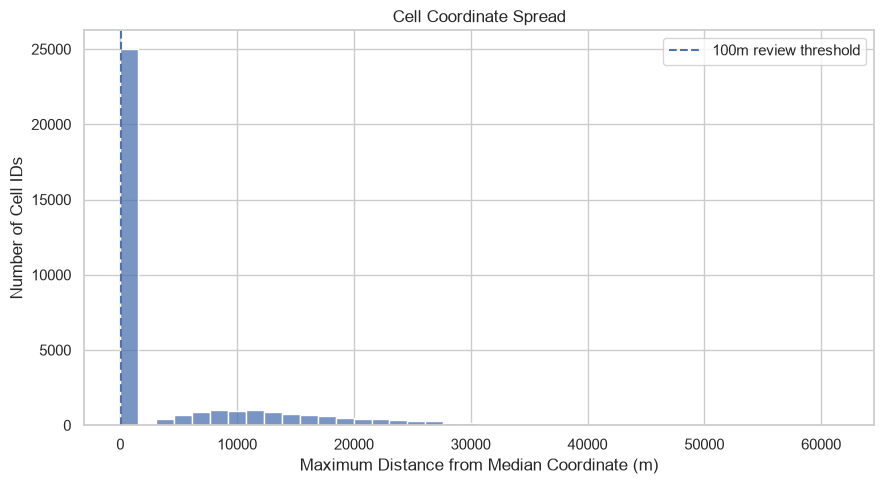

In [287]:
# 21: Summarise cell coordinate quality

cell_quality_summary = (
    cell_geo_profile["coordinate_quality_flag"]
    .value_counts()
    .rename_axis("coordinate_quality")
    .reset_index(name="cell_count")
)

cell_quality_summary["percentage"] = (
    cell_quality_summary["cell_count"]
    / cell_quality_summary["cell_count"].sum()
    * 100
)

display(cell_quality_summary)


plt.figure(figsize=(9, 5))

sns.histplot(
    data=cell_geo_profile,
    x="max_coordinate_spread_m",
    bins=40
)

plt.axvline(
    MAX_CELL_COORDINATE_SPREAD_M,
    linestyle="--",
    label=f"{MAX_CELL_COORDINATE_SPREAD_M}m review threshold"
)

plt.title("Cell Coordinate Spread")
plt.xlabel("Maximum Distance from Median Coordinate (m)")
plt.ylabel("Number of Cell IDs")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation: Cell Coordinate Quality Assessment

- **Total cell IDs analysed:** 35,928.
- **Acceptable coordinates:** 24,986 cells (69.54%) fall within the 100-metre coordinate consistency threshold.
- **Cells requiring review:** 10,942 cells (30.46%) exceed the 100-metre threshold.
- **Coordinate distribution:** The histogram shows a highly concentrated group of cells with very low coordinate spread, while the remaining cells exhibit substantial geographic variations.
- **Extreme inconsistencies:** Some cell IDs have coordinate deviations exceeding 30 km, with the maximum reaching approximately 61 km.

### Summary of Findings

Approximately 70% of cell IDs demonstrate acceptable geographic consistency, while 30% exhibit potentially significant coordinate inconsistencies.

The histogram reveals that coordinate inconsistencies are not limited to minor GPS variations; some cells have exceptionally large geographic deviations.

**Implication:** The 100-metre threshold provides a useful quality-control measure. Cells flagged for review should be investigated before assigning geographic locations or using cell-level coordinates for mobility and residential inference. Prioritise correcting or excluding cells with extreme coordinate deviations.

In [288]:
# 22: Filter cells for the initial inference run

valid_cells = cell_geo_profile.loc[
    cell_geo_profile["coordinate_quality_flag"] == "acceptable",
    "cell_id"
]


night_events_valid = night_events[
    night_events["cell_id"].isin(valid_cells)
].copy()


print("Nighttime events before cell filtering:", len(night_events))
print("Nighttime events after cell filtering:", len(night_events_valid))

print(
    "Percentage retained:",
    round(
        len(night_events_valid) / max(len(night_events), 1) * 100,
        2
    )
)

print(
    "Subscribers with valid nighttime events:",
    night_events_valid["msisdn"].nunique()
)

Nighttime events before cell filtering: 188785
Nighttime events after cell filtering: 69517
Percentage retained: 36.82
Subscribers with valid nighttime events: 2758


Methodological note: A cell flagged for coordinate review is not necessarily invalid. Multiple coordinates may reflect sector-level or network-recording differences. The 100-metre threshold is a starting assumption, and would be tested with alternative thresholds in subsequent notebooks.

#### Section 5 — Generate nighttime home-location candidates

In [289]:
# 23: Aggregate subscriber–cell activity

candidate_features = (
    night_events_valid.groupby(
        ["msisdn", "cell_id"],
        observed=True
    )
    .agg(
        nighttime_events=("datetime", "size"),
        distinct_nights=("night_id", "nunique"),
        median_latitude=("latitude", "median"),
        median_longitude=("longitude", "median"),
        first_night=("night_id", "min"),
        last_night=("night_id", "max")
    )
    .reset_index()
)


# Number of distinct nights on which each subscriber was observed
subscriber_observed_nights = (
    night_events_valid.groupby("msisdn", observed=True)
    ["night_id"]
    .nunique()
    .rename("observed_nights")
    .reset_index()
)


candidate_features = candidate_features.merge(
    subscriber_observed_nights,
    on="msisdn",
    how="left"
)


# Calculate each candidate cell's share of the subscriber's nighttime events
candidate_features["night_event_share"] = (
    candidate_features["nighttime_events"]
    / candidate_features.groupby(
        "msisdn",
        observed=True
    )["nighttime_events"].transform("sum")
)


# Calculate the share of observed nights on which the subscriber
# appeared at each candidate cell.
candidate_features["night_presence_ratio"] = (
    candidate_features["distinct_nights"]
    / candidate_features["observed_nights"].replace(0, np.nan)
)


display(candidate_features.head())

,msisdn,cell_id,nighttime_events,distinct_nights,median_latitude,median_longitude,first_night,last_night,observed_nights,night_event_share,night_presence_ratio
0,subscribers_00000,10235,2,2,-1.2556,36.7837,2026-02-06,2026-02-22,3,0.6667,0.6667
1,subscribers_00000,43702,1,1,-1.2793,36.7698,2026-02-08,2026-02-08,3,0.3333,0.3333
2,subscribers_00001,22964,1,1,-1.3071,36.8625,2026-02-22,2026-02-22,6,0.1667,0.1667
3,subscribers_00001,23709,2,2,-1.3096,36.8680,2026-02-08,2026-02-17,6,0.3333,0.3333
4,subscribers_00001,25964,1,1,-1.2925,36.8798,2026-02-05,2026-02-05,6,0.1667,0.1667


### Interpretation: Subscriber–Cell Nighttime Activity

- **Subscriber–cell combinations:** Each row represents a subscriber's nighttime activity at a specific cell.
- **Nighttime events:** The number of events varies across cells. For example, subscriber `00000` recorded 2 events at cell `10235` and 1 event at cell `43702`.
- **Distinct nights:** Some cells are observed across multiple nights, indicating repeated nighttime presence.
- **Night event share:** Measures the proportion of a subscriber's nighttime events occurring at a particular cell.
- **Night presence ratio:** Measures the proportion of a subscriber's observed nights during which they appeared at a particular cell.

### Summary of Findings

The table establishes a subscriber-level geographic profile of nighttime activity, identifying where subscribers are observed at night and how frequently they return to particular cells.

For example, subscriber `00000` has 66.67% of nighttime events associated with cell `10235`, compared with 33.33% for cell `43702`.

**Implication:** These features provide the foundation for identifying probable residential locations. Cells with higher nighttime event shares, repeated presence across distinct nights, and consistent geographic coordinates are stronger residential location candidates.

In [290]:
# 24: Inspect candidate coverage

candidate_coverage = (
    candidate_features.groupby("msisdn", observed=True)
    .agg(
        candidate_cells=("cell_id", "nunique"),
        observed_nights=("observed_nights", "first"),
        candidate_events=("nighttime_events", "sum")
    )
    .reset_index()
)

display(candidate_coverage.head())

print("Subscribers with candidate cells:", len(candidate_coverage))
print("Total candidate rows:", len(candidate_features))

,msisdn,candidate_cells,observed_nights,candidate_events
0,subscribers_00000,2,3,3
1,subscribers_00001,5,6,6
2,subscribers_00002,17,16,28
3,subscribers_00003,11,26,56
4,subscribers_00004,7,4,7


Subscribers with candidate cells: 2758
Total candidate rows: 24097


### Interpretation: Candidate Cell Coverage

- **Subscribers with candidate cells:** 2,758 ordinary subscribers have at least one identified nighttime candidate cell.
- **Total candidate rows:** 24,097 subscriber–cell combinations were generated.
- **Variation in geographic diversity:** The number of candidate cells varies considerably across subscribers. For example:
  - Subscriber `00000` has 2 candidate cells across 3 observed nights.
  - Subscriber `00002` has 17 candidate cells across 16 observed nights.
  - Subscriber `00003` has 11 candidate cells across 26 observed nights.
- **Candidate events:** The number of nighttime events associated with candidate cells also varies, reflecting differences in subscriber activity.

### Summary of Findings

The analysis identifies 2,758 subscribers with nighttime activity across 24,097 subscriber–cell combinations.

However, subscribers exhibit different levels of nighttime geographic diversity. Some have relatively few candidate cells, while others appear across many locations.

**Implication:** Candidate cell coverage establishes the search space for residential location inference. The next step is to rank candidate cells using nighttime event frequency, repeated presence, geographic consistency, and temporal stability to identify each subscriber's most probable residential location.

#### Section 6 — Method 1: Most frequent nighttime cell

This method selects the cell with the highest nighttime event count. It is simple and interpretable, but can be influenced by unusually frequent activity at a particular cell.

In [291]:
# 25: Run Method 1

method1_estimates = (
    candidate_features.sort_values(
        [
            "msisdn",
            "nighttime_events",
            "distinct_nights"
        ],
        ascending=[True, False, False]
    )
    .drop_duplicates("msisdn")
    .copy()
)


method1_estimates = method1_estimates.rename(
    columns={
        "cell_id": "method1_home_cell",
        "median_latitude": "method1_home_latitude",
        "median_longitude": "method1_home_longitude"
    }
)


method1_estimates = method1_estimates[
    [
        "msisdn",
        "method1_home_cell",
        "method1_home_latitude",
        "method1_home_longitude",
        "nighttime_events",
        "distinct_nights"
    ]
]


display(method1_estimates.head())

,msisdn,method1_home_cell,method1_home_latitude,method1_home_longitude,nighttime_events,distinct_nights
0,subscribers_00000,10235,-1.2556,36.7837,2,2
3,subscribers_00001,23709,-1.3096,36.8680,2,2
19,subscribers_00002,22951,-1.3194,36.8624,10,7
28,subscribers_00003,18804,-1.2737,36.8371,46,22
35,subscribers_00004,20162,-1.3641,36.8448,1,1


### Interpretation and Summary

- **Method 1 identifies each subscriber's potential home cell** by selecting the cell with the highest number of nighttime events, using the number of distinct nights as a secondary ranking criterion.
- The results show different levels of confidence in the estimates:

  - `subscribers_00000`: Cell 10235, observed 2 times across 2 nights.
  - `subscribers_00001`: Cell 23709, observed 2 times across 2 nights.
  - `subscribers_00002`: Cell 22951, observed 10 times across 7 nights.
  - `subscribers_00003`: Cell 18804, observed 46 times across 22 nights.
  - `subscribers_00004`: Cell 20162, observed once on 1 night.

**Key takeaway:** Method 1 provides a straightforward baseline for estimating home locations using nighttime activity. However, estimates supported by very few observations may be unreliable. Subscribers with repeated activity across multiple nights provide stronger evidence of a potential home location.

#### Section 7 — Method 2: Most distinct nights

This method selects the cell where the subscriber appeared across the greatest number of distinct nights. It prioritises repeated presence rather than raw event volume.

In [292]:
# 26: Run Method 2

method2_estimates = (
    candidate_features.sort_values(
        [
            "msisdn",
            "distinct_nights",
            "nighttime_events"
        ],
        ascending=[True, False, False]
    )
    .drop_duplicates("msisdn")
    .copy()
)


method2_estimates = method2_estimates.rename(
    columns={
        "cell_id": "method2_home_cell",
        "median_latitude": "method2_home_latitude",
        "median_longitude": "method2_home_longitude"
    }
)


method2_estimates = method2_estimates[
    [
        "msisdn",
        "method2_home_cell",
        "method2_home_latitude",
        "method2_home_longitude",
        "nighttime_events",
        "distinct_nights"
    ]
]


display(method2_estimates.head())

,msisdn,method2_home_cell,method2_home_latitude,method2_home_longitude,nighttime_events,distinct_nights
0,subscribers_00000,10235,-1.2556,36.7837,2,2
3,subscribers_00001,23709,-1.3096,36.8680,2,2
19,subscribers_00002,22951,-1.3194,36.8624,10,7
28,subscribers_00003,18804,-1.2737,36.8371,46,22
35,subscribers_00004,20162,-1.3641,36.8448,1,1


### Interpretation and Summary

- **Method 2 identifies each subscriber's potential home cell** by prioritising the cell where the subscriber was observed across the highest number of distinct nights. Nighttime event frequency is used as a secondary ranking criterion.
- The results show the following estimated home cells:

  - `subscribers_00000`: Cell 10235, observed across 2 nights with 2 events.
  - `subscribers_00001`: Cell 23709, observed across 2 nights with 2 events.
  - `subscribers_00002`: Cell 22951, observed across 7 nights with 10 events.
  - `subscribers_00003`: Cell 18804, observed across 22 nights with 46 events.
  - `subscribers_00004`: Cell 20162, observed across 1 night with 1 event.

**Key takeaway:** Method 2 prioritises consistency of nighttime presence over event frequency. This helps identify locations where subscribers repeatedly appear at night, potentially providing a more reliable home-location estimate than simply selecting the cell with the highest event count. However, subscribers with limited nighttime observations still have low-confidence estimates.

#### Section 8 — Method 3: Weighted nighttime scoring

We combine two signals:
- night_presence_ratio: proportion of observed nights on which the subscriber appeared at a candidate cell.
- night_event_share: proportion of the subscriber's nighttime events recorded at that cell.

In [293]:
# 27: Calculate weighted scores

candidate_features["weighted_night_score"] = (
    0.70 * candidate_features["night_presence_ratio"]
    + 0.30 * candidate_features["night_event_share"]
)

display(
    candidate_features.sort_values(
        ["msisdn", "weighted_night_score"],
        ascending=[True, False]
    ).head(20)
)

,msisdn,cell_id,nighttime_events,distinct_nights,median_latitude,median_longitude,first_night,last_night,observed_nights,night_event_share,night_presence_ratio,weighted_night_score
0,subscribers_00000,10235,2,2,-1.2556,36.7837,2026-02-06,2026-02-22,3,0.6667,0.6667,0.6667
1,subscribers_00000,43702,1,1,-1.2793,36.7698,2026-02-08,2026-02-08,3,0.3333,0.3333,0.3333
3,subscribers_00001,23709,2,2,-1.3096,36.8680,2026-02-08,2026-02-17,6,0.3333,0.3333,0.3333
2,subscribers_00001,22964,1,1,-1.3071,36.8625,2026-02-22,2026-02-22,6,0.1667,0.1667,0.1667
4,subscribers_00001,25964,1,1,-1.2925,36.8798,2026-02-05,2026-02-05,6,0.1667,0.1667,0.1667
5,subscribers_00001,26706,1,1,-1.2945,36.8822,2026-02-21,2026-02-21,6,0.1667,0.1667,0.1667
6,subscribers_00001,33863,1,1,-1.3601,36.9173,2026-02-24,2026-02-24,6,0.1667,0.1667,0.1667
19,subscribers_00002,22951,10,7,-1.3194,36.8624,2026-02-16,2026-02-25,16,0.3571,0.4375,0.4134
22,subscribers_00002,28284,3,3,-1.2197,36.8874,2026-02-05,2026-02-10,16,0.1071,0.1875,0.1634
7,subscribers_00002,14379,1,1,-1.2886,36.8176,2026-02-23,2026-02-23,16,0.0357,0.0625,0.0545


### Interpretation and Summary

- **The weighted nighttime score combines consistency and frequency of nighttime activity**, assigning 70% weight to `night_presence_ratio` and 30% to `night_event_share`.
- This prioritises cells where subscribers repeatedly appear across different nights rather than cells with occasional high activity.
- For example:
  - `subscribers_00000`: Cell 10235 scores **0.667**, making it the strongest candidate.
  - `subscribers_00001`: Cell 23709 scores **0.333**, ranking highest among the candidate cells.
  - `subscribers_00002`: Cell 22951 scores **0.413**, supported by 10 events across 7 distinct nights.

**Key takeaway:** The weighted scoring approach balances nighttime consistency with event frequency. By giving greater importance to repeated presence, it provides a more robust basis for identifying potential home cells than relying on event counts alone. Higher scores indicate stronger candidate home locations, although they do not guarantee residential occupancy.

In [294]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

candidate_features.to_csv(
    REPORT_PATH / "candidate_nighttime_activity_weighted_scores.csv",
    index=False
)

print("Candidates Nighttime Activity Weighted Scored report exported successfully.")

Candidates Nighttime Activity Weighted Scored report exported successfully.


In [295]:
# 28: Select the highest-scoring candidate

method3_estimates = (
    candidate_features.sort_values(
        [
            "msisdn",
            "weighted_night_score",
            "distinct_nights"
        ],
        ascending=[True, False, False]
    )
    .drop_duplicates("msisdn")
    .copy()
)


method3_estimates = method3_estimates.rename(
    columns={
        "cell_id": "method3_home_cell",
        "median_latitude": "method3_home_latitude",
        "median_longitude": "method3_home_longitude"
    }
)


method3_estimates = method3_estimates[
    [
        "msisdn",
        "method3_home_cell",
        "method3_home_latitude",
        "method3_home_longitude",
        "nighttime_events",
        "distinct_nights",
        "first_night",
        "last_night",
        "night_presence_ratio",
        "night_event_share",
        "weighted_night_score",
        "observed_nights"
    ]
]


display(method3_estimates.head())

,msisdn,method3_home_cell,method3_home_latitude,method3_home_longitude,nighttime_events,distinct_nights,first_night,last_night,night_presence_ratio,night_event_share,weighted_night_score,observed_nights
0,subscribers_00000,10235,-1.2556,36.7837,2,2,2026-02-06,2026-02-22,0.6667,0.6667,0.6667,3
3,subscribers_00001,23709,-1.3096,36.8680,2,2,2026-02-08,2026-02-17,0.3333,0.3333,0.3333,6
19,subscribers_00002,22951,-1.3194,36.8624,10,7,2026-02-16,2026-02-25,0.4375,0.3571,0.4134,16
28,subscribers_00003,18804,-1.2737,36.8371,46,22,2026-02-03,2026-02-28,0.8462,0.8214,0.8387,26
35,subscribers_00004,20162,-1.3641,36.8448,1,1,2026-02-06,2026-02-06,0.2500,0.1429,0.2179,4


### Interpretation and Summary

- **Method 3 selects the most likely home cell for each subscriber** using a weighted score that combines nighttime consistency (70%) and nighttime event frequency (30%).
- Each subscriber is assigned the candidate cell with the highest weighted nighttime score, with distinct nights used as a tie-breaker.
- Examples from the results:
  - `subscribers_00000`: Cell 10235, with a weighted score of **0.667** (2 events across 2 nights).
  - `subscribers_00001`: Cell 23709, with a score of **0.333** (2 events across 2 nights).
  - `subscribers_00002`: Cell 22951, with a score of **0.413** (10 events across 7 nights).
  - `subscribers_00003`: Cell 18804, with a score of **0.839** (46 events across 22 nights).
  - `subscribers_00004`: Cell 20162, with a score of **0.218** (1 event across 1 night).

**Key takeaway:** Method 3 balances repeated nighttime presence with activity frequency, making it a more comprehensive approach to home-cell inference. Higher scores indicate stronger evidence for a candidate home cell. However, confidence should also consider the total number of observed nights and events, since a high score based on limited observations may be misleading.

In [296]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

method3_estimates.to_csv(
    REPORT_PATH / "highest_scoring_nighttime_candidate.csv",
    index=False
)

print("Highest Scoring Nighttime Candidates report exported successfully.")

Highest Scoring Nighttime Candidates report exported successfully.


#### Section 9 — Method 4: Spatial clustering with DBSCAN

DBSCAN groups nearby candidate cell coordinates. This can help when a subscriber is observed across multiple nearby cells that cover the same residential area.

The clustering uses Haversine distance, which is suitable for latitude and longitude coordinates.

In [297]:
# 29: Define the DBSCAN inference function

def infer_home_using_dbscan(
    subscriber_candidates,
    eps_km=DBSCAN_EPS_KM,
    min_samples=DBSCAN_MIN_SAMPLES
):

    candidates = subscriber_candidates.copy()

    if len(candidates) < min_samples:
        return None

    coordinates_rad = np.radians(
        candidates[
            ["median_latitude", "median_longitude"]
        ].to_numpy()
    )

    dbscan = DBSCAN(
        eps=eps_km / EARTH_RADIUS_KM,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    candidates["cluster"] = dbscan.fit_predict(
        coordinates_rad
    )

    # Remove DBSCAN noise points.
    clustered = candidates[
        candidates["cluster"] != -1
    ].copy()

    if clustered.empty:
        return None

    # Select the cluster with the greatest repeated nighttime presence.
    cluster_summary = (
        clustered.groupby("cluster")
        .agg(
            total_distinct_nights=("distinct_nights", "sum"),
            total_events=("nighttime_events", "sum")
        )
        .reset_index()
        .sort_values(
            ["total_distinct_nights", "total_events"],
            ascending=False
        )
    )

    best_cluster = cluster_summary.iloc[0]["cluster"]

    selected = clustered[
        clustered["cluster"] == best_cluster
    ].copy()

    weights = selected["distinct_nights"].to_numpy(
        dtype=float
    )

    if weights.sum() == 0:
        weights = selected["nighttime_events"].to_numpy(
            dtype=float
        )

    if weights.sum() == 0:
        return None

    # Calculate weighted geographic centroid.
    home_latitude = np.average(
        selected["median_latitude"],
        weights=weights
    )

    home_longitude = np.average(
        selected["median_longitude"],
        weights=weights
    )

    return {
        "home_latitude": home_latitude,
        "home_longitude": home_longitude,
        "cluster_distinct_nights": selected["distinct_nights"].sum(),
        "cluster_events": selected["nighttime_events"].sum(),
        "cluster_cell_count": selected["cell_id"].nunique()
    }

In [298]:
# 30: Run DBSCAN for each subscriber

dbscan_results = []

for msisdn, group in candidate_features.groupby(
    "msisdn",
    observed=True
):

    result = infer_home_using_dbscan(group)

    if result is not None:
        dbscan_results.append({
            "msisdn": msisdn,
            **result
        })


dbscan_columns = [
    "msisdn",
    "home_latitude",
    "home_longitude",
    "cluster_distinct_nights",
    "cluster_events",
    "cluster_cell_count"
]

method4_estimates = pd.DataFrame(
    dbscan_results,
    columns=dbscan_columns
)


method4_estimates = method4_estimates.rename(
    columns={
        "home_latitude": "method4_home_latitude",
        "home_longitude": "method4_home_longitude"
    }
)


display(method4_estimates.head())

print("Subscribers with DBSCAN estimates:", len(method4_estimates))

,msisdn,method4_home_latitude,method4_home_longitude,cluster_distinct_nights,cluster_events,cluster_cell_count
0,subscribers_00001,-1.3088,36.8662,3,3,2
1,subscribers_00002,-1.2855,36.8307,6,6,6
2,subscribers_00003,-1.2735,36.8369,23,47,2
3,subscribers_00004,-1.3870,36.7660,2,2,2
4,subscribers_00005,-1.3296,36.7565,12,12,12


Subscribers with DBSCAN estimates: 2073


### Interpretation and Summary

- **Method 4 uses DBSCAN clustering** to identify geographically concentrated nighttime activity and estimate each subscriber's potential home location.
- The algorithm groups nearby candidate cells, removes geographic outliers (noise), and selects the cluster with the highest number of distinct nighttime observations.
- The estimated home coordinates are calculated using a weighted geographic centroid, with distinct nights determining the weights.
- **2,073 subscribers received DBSCAN-based home-location estimates.** This means the method successfully identified a qualifying geographic cluster for these subscribers.
- The results show different levels of supporting evidence:
  - `subscribers_00001`: 3 distinct nights, 3 events across 2 cells.
  - `subscribers_00002`: 6 distinct nights, 6 events across 6 cells.
  - `subscribers_00003`: 23 distinct nights, 47 events across 2 cells.
  - `subscribers_00004`: 2 distinct nights, 2 events across 2 cells.
  - `subscribers_00005`: 12 distinct nights, 12 events across 12 cells.

**Key takeaway:** DBSCAN provides a geographically informed approach to home-location inference by identifying clusters of nearby nighttime cells rather than selecting a single cell. It is particularly useful where subscribers move between neighbouring cell towers around their residence. However, only 2,073 subscribers received estimates, so coverage and confidence should be evaluated alongside the other methods.

In [299]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

method4_estimates.to_csv(
    REPORT_PATH / "DBSCAN_estimates_for_each_subscriber.csv",
    index=False
)

print("DBSCAN estimates for each subscriber report exported successfully.")

DBSCAN estimates for each subscriber report exported successfully.


#### Section 10 — Consolidate inference estimates

Subscribers who have no usable nighttime observations must remain in the final table, with an explicit insufficient-evidence status.

In [300]:
# 31: Create a complete subscriber-level results table

all_ordinary_subscribers = pd.DataFrame({
    "msisdn": pd.Series(
        ordinary_ids,
        dtype="string"
    )
})


home_estimates = (
    all_ordinary_subscribers
    .merge(
        method1_estimates,
        on="msisdn",
        how="left"
    )
    .merge(
        method2_estimates,
        on="msisdn",
        how="left"
    )
    .merge(
        method3_estimates,
        on="msisdn",
        how="left"
    )
    .merge(
        method4_estimates,
        on="msisdn",
        how="left"
    )
)


# Count valid nighttime coverage per subscriber.
night_coverage = (
    night_events_valid.groupby("msisdn", observed=True)
    .agg(
        valid_nighttime_events=("datetime", "size"),
        valid_distinct_nights=("night_id", "nunique"),
        valid_nighttime_cells=("cell_id", "nunique")
    )
    .reset_index()
)


home_estimates = home_estimates.merge(
    night_coverage,
    on="msisdn",
    how="left"
)


coverage_columns = [
    "valid_nighttime_events",
    "valid_distinct_nights",
    "valid_nighttime_cells"
]

for col in coverage_columns:
    home_estimates[col] = (
        home_estimates[col]
        .fillna(0)
        .astype(int)
    )


home_estimates["inference_status"] = np.where(
    (
        home_estimates["valid_distinct_nights"]
        >= MIN_DISTINCT_NIGHTS
    )
    & (
        home_estimates["method3_home_latitude"].notna()
    ),
    "estimated",
    "insufficient_evidence"
)


display(home_estimates.head())

,msisdn,method1_home_cell,method1_home_latitude,method1_home_longitude,nighttime_events_x,distinct_nights_x,method2_home_cell,method2_home_latitude,method2_home_longitude,nighttime_events_y,distinct_nights_y,method3_home_cell,method3_home_latitude,method3_home_longitude,nighttime_events,distinct_nights,first_night,last_night,night_presence_ratio,night_event_share,weighted_night_score,observed_nights,method4_home_latitude,method4_home_longitude,cluster_distinct_nights,cluster_events,cluster_cell_count,valid_nighttime_events,valid_distinct_nights,valid_nighttime_cells,inference_status
0,subscribers_00000,10235,-1.2556,36.7837,2.0000,2.0000,10235,-1.2556,36.7837,2.0000,2.0000,10235,-1.2556,36.7837,2.0000,2.0000,2026-02-06,2026-02-22,0.6667,0.6667,0.6667,3.0000,NaN,NaN,NaN,NaN,NaN,3,3,2,estimated
1,subscribers_00001,23709,-1.3096,36.8680,2.0000,2.0000,23709,-1.3096,36.8680,2.0000,2.0000,23709,-1.3096,36.8680,2.0000,2.0000,2026-02-08,2026-02-17,0.3333,0.3333,0.3333,6.0000,-1.3088,36.8662,3.0000,3.0000,2.0000,6,6,5,estimated
2,subscribers_00002,22951,-1.3194,36.8624,10.0000,7.0000,22951,-1.3194,36.8624,10.0000,7.0000,22951,-1.3194,36.8624,10.0000,7.0000,2026-02-16,2026-02-25,0.4375,0.3571,0.4134,16.0000,-1.2855,36.8307,6.0000,6.0000,6.0000,28,16,17,estimated
3,subscribers_00003,18804,-1.2737,36.8371,46.0000,22.0000,18804,-1.2737,36.8371,46.0000,22.0000,18804,-1.2737,36.8371,46.0000,22.0000,2026-02-03,2026-02-28,0.8462,0.8214,0.8387,26.0000,-1.2735,36.8369,23.0000,47.0000,2.0000,56,26,11,estimated
4,subscribers_00004,20162,-1.3641,36.8448,1.0000,1.0000,20162,-1.3641,36.8448,1.0000,1.0000,20162,-1.3641,36.8448,1.0000,1.0000,2026-02-06,2026-02-06,0.2500,0.1429,0.2179,4.0000,-1.3870,36.7660,2.0000,2.0000,2.0000,7,4,7,estimated


### Interpretation and Summary

- **The complete subscriber-level results table combines all four home-location inference methods** into a single dataset, allowing their estimated coordinates and supporting evidence to be compared for each subscriber.
- The dataset contains **2,813 ordinary subscribers**, with nighttime activity coverage summarised using total nighttime events, distinct nights and unique nighttime cells.
- **Inference coverage:**
  - Methods 1, 2 and 3 produced estimates for 2,758 subscribers.
  - Method 4 (DBSCAN) produced estimates for 2,073 subscribers.
  - 740 subscribers did not receive a DBSCAN estimate, indicating that no qualifying geographic cluster was identified.
- **Inference status:**
  - 2,539 subscribers (90.3%) were classified as `estimated`.
  - 274 subscribers (9.7%) were classified as `insufficient_evidence`.
- The inference status is determined by the minimum distinct-night requirement and the availability of a Method 3 estimate.

**Key takeaway:** The consolidated dataset provides a unified view of subscriber home-location estimates across four approaches. Most subscribers have sufficient evidence for an estimated home location, while a smaller group requires additional nighttime observations. The table also provides the foundation for comparing methods, assessing confidence and identifying subscribers whose inferred home locations are potentially unreliable.

In [301]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

home_estimates.to_csv(
    REPORT_PATH / "home_estimates.csv",
    index=False
)

print("Home estimates report exported successfully.")

Home estimates report exported successfully.


,inference_status,subscriber_count,percentage
0,estimated,2539,90.2595
1,insufficient_evidence,274,9.7405


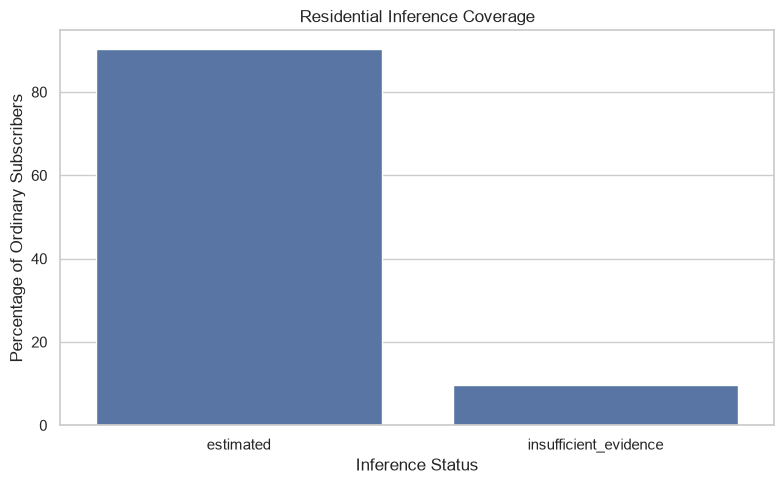

In [302]:
# 32: Check subscriber coverage

inference_status_summary = (
    home_estimates["inference_status"]
    .value_counts()
    .rename_axis("inference_status")
    .reset_index(name="subscriber_count")
)

inference_status_summary["percentage"] = (
    inference_status_summary["subscriber_count"]
    / inference_status_summary["subscriber_count"].sum()
    * 100
)

display(inference_status_summary)


plt.figure(figsize=(8, 5))

sns.barplot(
    data=inference_status_summary,
    x="inference_status",
    y="percentage"
)

plt.title("Residential Inference Coverage")
plt.xlabel("Inference Status")
plt.ylabel("Percentage of Ordinary Subscribers")
plt.tight_layout()
plt.show()

### Interpretation and Summary

- **The residential inference process successfully estimated potential home locations for 2,539 out of 2,813 ordinary subscribers (90.26%).**
- **274 subscribers (9.74%)** had insufficient evidence to produce a reliable home-location estimate.
- The high coverage indicates that the methodology can identify potential residential locations for the majority of subscribers using their nighttime network activity.
- The remaining subscribers may require more nighttime observations or a longer observation period to improve inference reliability.

**Key takeaway:** The residential inference framework achieves approximately **90.3% coverage**, demonstrating strong overall coverage. However, successful inference does not necessarily guarantee accuracy; further validation of estimated home locations is required before treating them as confirmed residential addresses.

#### Section 11 — Assign initial confidence levels

The weighted score is a relative candidate score. It should not be described as the probability that the inferred location is correct.

In [303]:
# 33: Confidence classification

home_estimates["confidence"] = "low"


home_estimates.loc[
    (
        home_estimates["inference_status"] == "estimated"
    )
    & (
        home_estimates["weighted_night_score"]
        >= MEDIUM_CONFIDENCE_THRESHOLD
    ),
    "confidence"
] = "medium"


home_estimates.loc[
    (
        home_estimates["inference_status"] == "estimated"
    )
    & (
        home_estimates["weighted_night_score"]
        >= HIGH_CONFIDENCE_THRESHOLD
    ),
    "confidence"
] = "high"


home_estimates.loc[
    home_estimates["inference_status"] == "insufficient_evidence",
    "confidence"
] = "insufficient_evidence"


display(
    home_estimates["confidence"]
    .value_counts(dropna=False)
    .to_frame("subscriber_count")
)

,subscriber_count
confidence,
low,1318
high,1112
insufficient_evidence,274
medium,109


### Interpretation and Summary

- **Low confidence:** 1,318 subscribers (46.9%) fall into this category. Their estimated home locations have weaker supporting nighttime activity patterns.
- **High confidence:** 1,112 subscribers (39.5%) have stronger evidence supporting their inferred home locations.
- **Medium confidence:** 109 subscribers (3.9%) have moderate supporting evidence.
- **Insufficient evidence:** 274 subscribers (9.7%) do not meet the minimum requirements for reliable home-location inference.

**Key takeaway:** Although 90.3% of subscribers received home-location estimates, only 39.5% achieved high confidence. The large proportion of low-confidence estimates suggests that inference coverage alone does not guarantee reliability. Further validation and additional nighttime observations could improve confidence.

**Overall:** The framework successfully generates estimates for most subscribers, but improving inference quality should be the next priority.

,confidence,subscriber_count,percentage
0,low,1318,46.8539
1,high,1112,39.5308
2,insufficient_evidence,274,9.7405
3,medium,109,3.8749


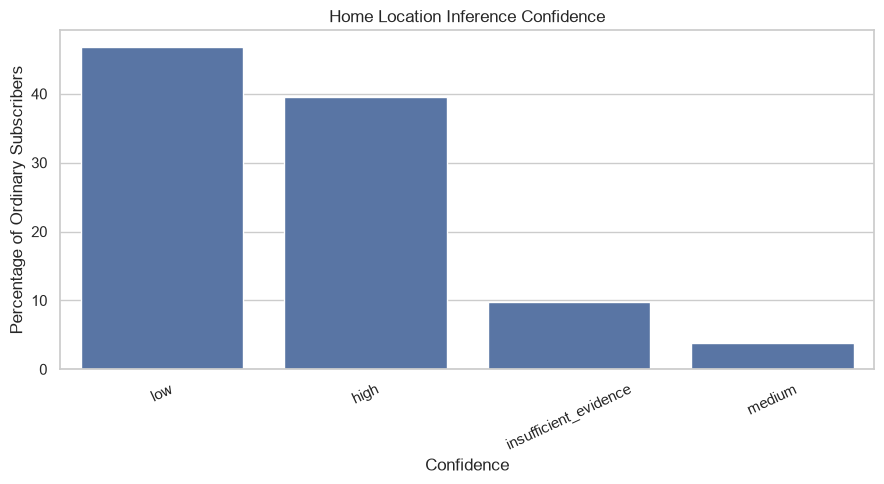

In [304]:
# 34: Visualise confidence distribution

confidence_summary = (
    home_estimates["confidence"]
    .value_counts()
    .rename_axis("confidence")
    .reset_index(name="subscriber_count")
)

confidence_summary["percentage"] = (
    confidence_summary["subscriber_count"]
    / confidence_summary["subscriber_count"].sum()
    * 100
)

display(confidence_summary)


plt.figure(figsize=(9, 5))

sns.barplot(
    data=confidence_summary,
    x="confidence",
    y="percentage"
)

plt.title("Home Location Inference Confidence")
plt.xlabel("Confidence")
plt.ylabel("Percentage of Ordinary Subscribers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Interpretation and Summary

- **Low confidence:** 1,318 subscribers (46.85%) have relatively weak supporting evidence for their inferred home locations.
- **High confidence:** 1,112 subscribers (39.53%) have strong supporting nighttime activity patterns.
- **Insufficient evidence:** 274 subscribers (9.74%) do not meet the minimum requirements for reliable inference.
- **Medium confidence:** 109 subscribers (3.87%) have moderate supporting evidence.

**Key takeaway:** The results show that although the framework estimates home locations for approximately 90.3% of ordinary subscribers, only 39.5% achieve high confidence. Nearly half fall into the low-confidence category, highlighting the need for stronger validation and additional nighttime observations.

**Overall:** The framework demonstrates good inference coverage, but improving the reliability of estimated residential locations remains the primary challenge.

#### Section 12 — Evaluate using synthetic reference labels

Only at this stage do we access location_target.

The synthetic data simulator's location_target == "home" records are used to construct a synthetic reference home coordinate for each subscriber.

This is an evaluation reference supplied by the simulator. It is not independent ground truth from household surveys, GPS validation, or field verification.

location_place is retained as a categorical diagnostic field but is not needed to calculate the home-location distance error.

In [305]:
# 35: Construct synthetic reference home coordinates

# EVALUATION ONLY.
# Do not move this logic into the inference section.

evaluation_source = df_residential.copy()

ground_truth_home = (
    evaluation_source[
        evaluation_source["location_target"]
        .astype("string")
        .str.strip()
        .str.lower()
        == "home"
    ]
    .groupby("msisdn", observed=True)
    .agg(
        reference_home_latitude=("latitude", "median"),
        reference_home_longitude=("longitude", "median"),
        reference_home_events=("datetime", "size")
    )
    .reset_index()
)


print(
    "Subscribers with synthetic home references:",
    len(ground_truth_home)
)

display(ground_truth_home.head())

Subscribers with synthetic home references: 2813


,msisdn,reference_home_latitude,reference_home_longitude,reference_home_events
0,subscribers_00000,-1.2556,36.7837,11
1,subscribers_00001,-1.2936,36.8853,230
2,subscribers_00002,-1.3194,36.8624,96
3,subscribers_00003,-1.2737,36.8371,144
4,subscribers_00004,-1.3892,36.7614,81


### Interpretation and Summary

- **Synthetic ground-truth home coordinates were successfully generated for 2,813 subscribers** using records labelled `home` in the `df_residential` dataset.
- For each subscriber, the median latitude and longitude were calculated to establish a representative reference home location.
- `reference_home_events` records the number of home-labelled observations supporting each reference location.
- The sample shows varying levels of reference coverage:
  - `subscribers_00000`: 11 home observations.
  - `subscribers_00001`: 230 home observations.
  - `subscribers_00002`: 96 home observations.
  - `subscribers_00003`: 144 home observations.
  - `subscribers_00004`: 81 home observations.

**Key takeaway:** The synthetic reference dataset provides a benchmark against which the inferred home coordinates from Methods 1–4 can be evaluated. However, the number of home observations varies considerably between subscribers, which may affect the reliability of individual reference coordinates. These references are intended for evaluation, not for training or influencing the inference methods.

In [306]:
# 36: Merge reference coordinates with estimates

evaluation_df = home_estimates.merge(
    ground_truth_home,
    on="msisdn",
    how="left"
)

display(evaluation_df.head())

print(
    "Subscribers with a synthetic home reference:",
    evaluation_df["reference_home_latitude"].notna().sum()
)

,msisdn,method1_home_cell,method1_home_latitude,method1_home_longitude,nighttime_events_x,distinct_nights_x,method2_home_cell,method2_home_latitude,method2_home_longitude,nighttime_events_y,distinct_nights_y,method3_home_cell,method3_home_latitude,method3_home_longitude,nighttime_events,distinct_nights,first_night,last_night,night_presence_ratio,night_event_share,weighted_night_score,observed_nights,method4_home_latitude,method4_home_longitude,cluster_distinct_nights,cluster_events,cluster_cell_count,valid_nighttime_events,valid_distinct_nights,valid_nighttime_cells,inference_status,confidence,reference_home_latitude,reference_home_longitude,reference_home_events
0,subscribers_00000,10235,-1.2556,36.7837,2.0000,2.0000,10235,-1.2556,36.7837,2.0000,2.0000,10235,-1.2556,36.7837,2.0000,2.0000,2026-02-06,2026-02-22,0.6667,0.6667,0.6667,3.0000,NaN,NaN,NaN,NaN,NaN,3,3,2,estimated,high,-1.2556,36.7837,11
1,subscribers_00001,23709,-1.3096,36.8680,2.0000,2.0000,23709,-1.3096,36.8680,2.0000,2.0000,23709,-1.3096,36.8680,2.0000,2.0000,2026-02-08,2026-02-17,0.3333,0.3333,0.3333,6.0000,-1.3088,36.8662,3.0000,3.0000,2.0000,6,6,5,estimated,low,-1.2936,36.8853,230
2,subscribers_00002,22951,-1.3194,36.8624,10.0000,7.0000,22951,-1.3194,36.8624,10.0000,7.0000,22951,-1.3194,36.8624,10.0000,7.0000,2026-02-16,2026-02-25,0.4375,0.3571,0.4134,16.0000,-1.2855,36.8307,6.0000,6.0000,6.0000,28,16,17,estimated,medium,-1.3194,36.8624,96
3,subscribers_00003,18804,-1.2737,36.8371,46.0000,22.0000,18804,-1.2737,36.8371,46.0000,22.0000,18804,-1.2737,36.8371,46.0000,22.0000,2026-02-03,2026-02-28,0.8462,0.8214,0.8387,26.0000,-1.2735,36.8369,23.0000,47.0000,2.0000,56,26,11,estimated,high,-1.2737,36.8371,144
4,subscribers_00004,20162,-1.3641,36.8448,1.0000,1.0000,20162,-1.3641,36.8448,1.0000,1.0000,20162,-1.3641,36.8448,1.0000,1.0000,2026-02-06,2026-02-06,0.2500,0.1429,0.2179,4.0000,-1.3870,36.7660,2.0000,2.0000,2.0000,7,4,7,estimated,low,-1.3892,36.7614,81


Subscribers with a synthetic home reference: 2813


### Interpretation and Summary

- **The merge successfully combined the inferred home locations with the synthetic reference coordinates** using `msisdn` as the common identifier.
- The resulting evaluation dataset contains **2,813 subscribers** and 35 columns, incorporating estimates from all four methods alongside their reference coordinates.
- All **2,813 subscribers (100%)** have corresponding synthetic reference home coordinates.
- The dataset also retains supporting information, including reference home events, nighttime activity, weighted scores, confidence levels and inference status.

**Key takeaway:** The merged dataset provides a complete evaluation framework for comparing the four home-location inference methods against synthetic reference coordinates. The next step is to calculate geographic distance errors (in kilometres) between each method's estimated home location and the corresponding reference location to determine which method performs best.

In [307]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(
    REPORT_PATH / "subscribers_with_a_synthetic_home_reference.csv",
    index=False
)

print("Subscribers with a synthetic home reference report exported successfully.")

Subscribers with a synthetic home reference report exported successfully.


In [308]:
# 37: Calculate distance error for Method 3

evaluation_df["method3_error_km"] = np.nan

valid_method3 = evaluation_df.dropna(
    subset=[
        "method3_home_latitude",
        "method3_home_longitude",
        "reference_home_latitude",
        "reference_home_longitude"
    ]
).index


evaluation_df.loc[
    valid_method3,
    "method3_error_km"
] = haversine_km(
    evaluation_df.loc[
        valid_method3,
        "method3_home_latitude"
    ],
    evaluation_df.loc[
        valid_method3,
        "method3_home_longitude"
    ],
    evaluation_df.loc[
        valid_method3,
        "reference_home_latitude"
    ],
    evaluation_df.loc[
        valid_method3,
        "reference_home_longitude"
    ]
)


evaluation_df["method3_error_m"] = (
    evaluation_df["method3_error_km"] * 1000
)


display(
    evaluation_df[
        [
            "msisdn",
            "method3_home_latitude",
            "method3_home_longitude",
            "reference_home_latitude",
            "reference_home_longitude",
            "method3_error_m"
        ]
    ].head()
)

,msisdn,method3_home_latitude,method3_home_longitude,reference_home_latitude,reference_home_longitude,method3_error_m
0,subscribers_00000,-1.2556,36.7837,-1.2556,36.7837,0.0000
1,subscribers_00001,-1.3096,36.8680,-1.2936,36.8853,"2,619.9023"
2,subscribers_00002,-1.3194,36.8624,-1.3194,36.8624,0.0000
3,subscribers_00003,-1.2737,36.8371,-1.2737,36.8371,0.0000
4,subscribers_00004,-1.3641,36.8448,-1.3892,36.7614,"9,681.9921"


### Interpretation and Summary

- **Method 3 calculates the geographic distance error** between each subscriber's inferred home coordinates and their synthetic reference home coordinates using the Haversine formula.
- The first five records show varying levels of accuracy:
  - `subscribers_00000`: 0 metres error (exact match).
  - `subscribers_00001`: 2,619.9 metres error (approximately 2.62 km).
  - `subscribers_00002`: 0 metres error (exact match).
  - `subscribers_00003`: 0 metres error (exact match).
  - `subscribers_00004`: 9,681.99 metres error (approximately 9.68 km).

- Zero error indicates that the inferred coordinates match the synthetic reference coordinates.

**Key takeaway:** Method 3 produces accurate estimates for some subscribers but shows substantial geographic deviations for others. This highlights the importance of evaluating overall distance-error metrics, particularly median error, mean error and the percentage of estimates within 1 km, 3 km and 5 km.

**Next step:** Evaluate the error distribution across all subscribers to determine the overall accuracy and reliability of Method 3.

In [309]:
# Export the report

REPORT_PATH = PROJECT_ROOT / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

evaluation_df.to_csv(
    REPORT_PATH / "method3_distance_error.csv",
    index=False
)

print("Method3 Distance Error report exported successfully.")

Method3 Distance Error report exported successfully.


In [310]:
# 38: Calculate Method 3 evaluation metrics

valid_evaluation = evaluation_df.dropna(
    subset=["method3_error_m"]
).copy()


if len(valid_evaluation) > 0:

    evaluation_metrics = pd.DataFrame({
        "metric": [
            "Subscribers evaluated",
            "Mean error (m)",
            "Median error (m)",
            "90th percentile error (m)",
            "Within 500m (%)",
            "Within 1km (%)",
            "Within 2km (%)"
        ],
        "value": [
            len(valid_evaluation),
            valid_evaluation["method3_error_m"].mean(),
            valid_evaluation["method3_error_m"].median(),
            valid_evaluation["method3_error_m"].quantile(0.90),
            (
                valid_evaluation["method3_error_m"] <= 500
            ).mean() * 100,
            (
                valid_evaluation["method3_error_m"] <= 1000
            ).mean() * 100,
            (
                valid_evaluation["method3_error_m"] <= 2000
            ).mean() * 100
        ]
    })

else:

    evaluation_metrics = pd.DataFrame(
        columns=["metric", "value"]
    )

display(evaluation_metrics)

,metric,value
0,Subscribers evaluated,"2,758.0000"
1,Mean error (m),"3,090.8868"
2,Median error (m),434.8690
3,90th percentile error (m),"9,695.9348"
4,Within 500m (%),50.7614
5,Within 1km (%),55.8013
6,Within 2km (%),63.1980


### Interpretation and Summary

- **Subscribers evaluated:** Method 3 successfully produced home-location estimates for 2,758 subscribers.
- **Mean error:** 3,090.89 metres (approximately 3.09 km), indicating that some large errors are pulling the average upward.
- **Median error:** 434.87 metres, meaning half of the estimated home locations are within approximately 435 metres of their synthetic reference locations.
- **90th percentile error:** 9.70 km, indicating substantial deviations among the least accurate estimates.
- **Within 500 metres:** 50.76% of subscribers.
- **Within 1 km:** 55.80% of subscribers.
- **Within 2 km:** 63.20% of subscribers.

**Key takeaway:** Method 3 demonstrates reasonably good accuracy for a substantial proportion of subscribers, with a median error below 500 metres. However, the difference between the mean and median errors suggests a long-tailed error distribution, where a smaller group of subscribers has considerably inaccurate estimates.

**Overall:** Method 3 provides promising residential location estimates, but outliers and low-confidence predictions need further investigation to improve reliability.

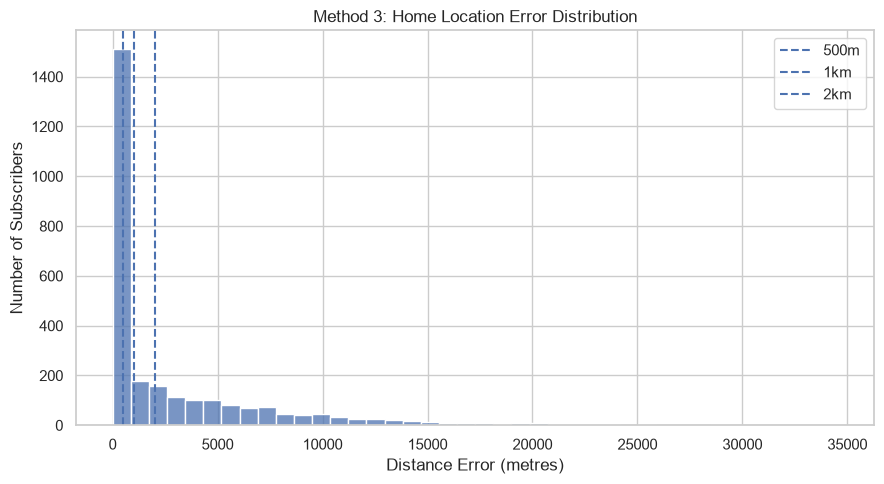

In [311]:
# 39: Visualise Method 3 error distribution

if len(valid_evaluation) > 0:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=valid_evaluation,
        x="method3_error_m",
        bins=40
    )

    plt.axvline(
        500,
        linestyle="--",
        label="500m"
    )

    plt.axvline(
        1000,
        linestyle="--",
        label="1km"
    )

    plt.axvline(
        2000,
        linestyle="--",
        label="2km"
    )

    plt.title("Method 3: Home Location Error Distribution")
    plt.xlabel("Distance Error (metres)")
    plt.ylabel("Number of Subscribers")
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print("No subscribers available for Method 3 evaluation.")

### Interpretation and Summary

- **Highly right-skewed distribution:** Most subscribers have relatively low home-location estimation errors, with a large concentration around the 500-metre mark.
- **Strong initial accuracy:** The majority of estimates are clustered close to the synthetic reference locations.
- **Long error tail:** A smaller group of subscribers has substantial errors, with some estimates exceeding 10 km.
- **500m, 1km and 2km thresholds:** The dashed lines provide reference accuracy benchmarks, showing that a considerable proportion of estimates fall within these distances.

**Key takeaway:** Method 3 performs reasonably well for many subscribers, but accuracy varies considerably. The long tail indicates that a smaller group of subscribers has poorly estimated home locations.

**Recommendation:** Investigate high-error subscribers, particularly those with multiple nighttime locations or weak residential patterns, and consider using confidence scores to filter unreliable predictions.

#### Section 13 — Compare all four inference methods

In [312]:
# 40 - Calculate comparable metrics

method_columns = {
    "Method 1 - Event Frequency": (
        "method1_home_latitude",
        "method1_home_longitude"
    ),

    "Method 2 - Distinct Nights": (
        "method2_home_latitude",
        "method2_home_longitude"
    ),

    "Method 3 - Weighted Score": (
        "method3_home_latitude",
        "method3_home_longitude"
    ),

    "Method 4 - DBSCAN": (
        "method4_home_latitude",
        "method4_home_longitude"
    )
}


method_comparison = []


for method_name, (lat_col, lon_col) in method_columns.items():

    temp = evaluation_df.dropna(
        subset=[
            lat_col,
            lon_col,
            "reference_home_latitude",
            "reference_home_longitude"
        ]
    ).copy()

    if temp.empty:
        continue

    errors_m = haversine_km(
        temp[lat_col],
        temp[lon_col],
        temp["reference_home_latitude"],
        temp["reference_home_longitude"]
    ) * 1000

    method_comparison.append({
        "method": method_name,
        "subscribers_evaluated": len(temp),
        "mean_error_m": np.mean(errors_m),
        "median_error_m": np.median(errors_m),
        "p90_error_m": np.percentile(errors_m, 90),
        "within_500m_pct": np.mean(errors_m <= 500) * 100,
        "within_1km_pct": np.mean(errors_m <= 1000) * 100,
        "within_2km_pct": np.mean(errors_m <= 2000) * 100
    })


method_comparison = pd.DataFrame(method_comparison)

if not method_comparison.empty:
    method_comparison = method_comparison.sort_values(
        "median_error_m"
    )

display(method_comparison)

,method,subscribers_evaluated,mean_error_m,median_error_m,p90_error_m,within_500m_pct,within_1km_pct,within_2km_pct
3,Method 4 - DBSCAN,2073,984.0233,268.3892,"2,711.2039",64.7371,77.4240,86.6860
0,Method 1 - Event Frequency,2758,"3,090.2081",432.7864,"9,695.9348",50.7977,55.8376,63.2342
1,Method 2 - Distinct Nights,2758,"3,090.8868",434.8690,"9,695.9348",50.7614,55.8013,63.1980
2,Method 3 - Weighted Score,2758,"3,090.8868",434.8690,"9,695.9348",50.7614,55.8013,63.1980


### Interpretation and Summary

The evaluation results indicate that **Method 4 (DBSCAN) delivers the strongest residential location accuracy among the four approaches in the current evaluation**.

Key findings:

- **DBSCAN achieves the lowest mean and median errors**, at approximately 984 metres and 268 metres, respectively.
- Approximately **64.74% of DBSCAN estimates fall within 500 metres**, 77.42% within 1 kilometre, and 86.69% within 2 kilometres of the synthetic reference home locations.
- DBSCAN also achieves a substantially lower 90th-percentile error (2.71 km), compared with approximately 9.70 km for the other three methods.
- Methods 1 (Event Frequency), 2 (Distinct Nights), and 3 (Weighted Score) perform almost identically, suggesting that the additional weighted scoring approach provides limited improvement over selecting the cell with the greatest number of distinct nighttime observations.
- However, DBSCAN evaluates 2,073 subscribers, compared with 2,758 for the other methods. Its lower coverage is an important limitation.

**Key takeaway:** DBSCAN is the most promising approach based on the current accuracy metrics. However, its performance must be compared against the other methods on a common subscriber cohort before concluding that it is definitively superior. Further investigation of its coverage limitations and parameter sensitivity is also required.

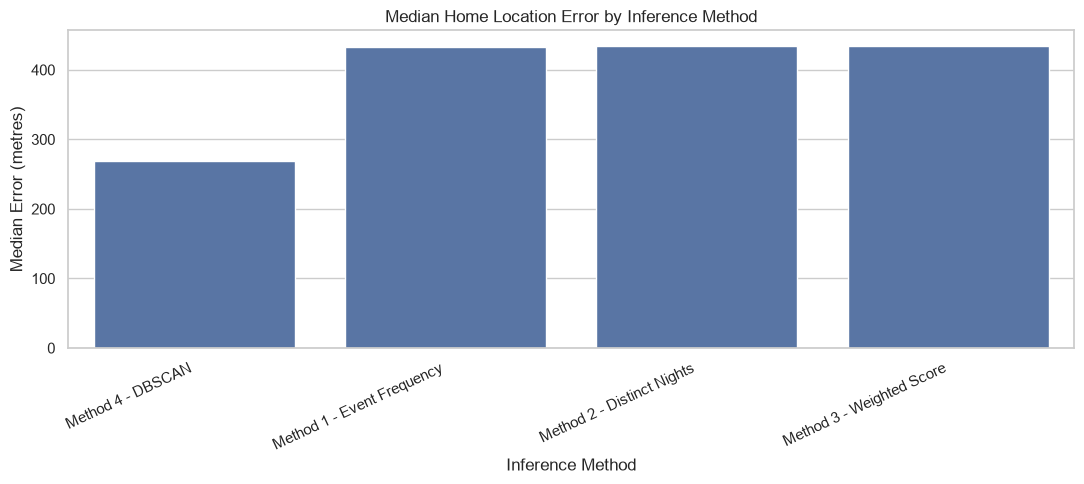

In [313]:
# 41: Compare median errors

if not method_comparison.empty:

    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=method_comparison,
        x="method",
        y="median_error_m"
    )

    plt.title("Median Home Location Error by Inference Method")
    plt.xlabel("Inference Method")
    plt.ylabel("Median Error (metres)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

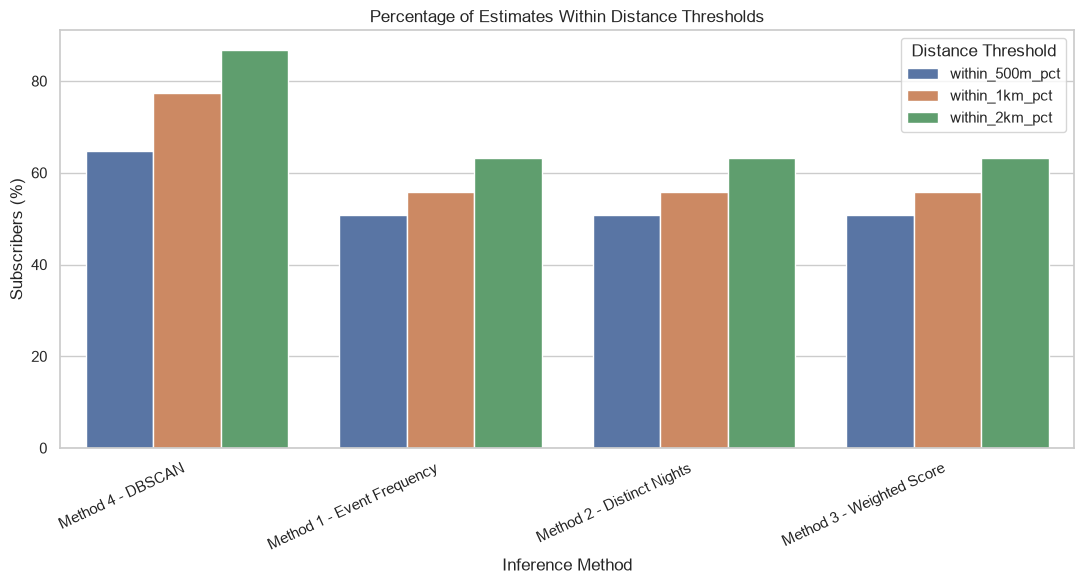

In [314]:
# 42: Compare percentage within distance thresholds

if not method_comparison.empty:

    threshold_columns = [
        "within_500m_pct",
        "within_1km_pct",
        "within_2km_pct"
    ]

    threshold_comparison = method_comparison[
        ["method"] + threshold_columns
    ].melt(
        id_vars="method",
        var_name="distance_threshold",
        value_name="percentage"
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=threshold_comparison,
        x="method",
        y="percentage",
        hue="distance_threshold"
    )

    plt.title("Percentage of Estimates Within Distance Thresholds")
    plt.xlabel("Inference Method")
    plt.ylabel("Subscribers (%)")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="Distance Threshold")
    plt.tight_layout()
    plt.show()

### Interpretation and Summary

- **Method 4 (DBSCAN) consistently outperforms all other methods** across all three distance thresholds.
- Approximately **65% of subscribers** have home locations estimated within 500m, compared with 77% within 1km and 87% within 2km.
- Methods 1 (Event Frequency), 2 (Distinct Nights), and 3 (Weighted Score) show almost identical performance, achieving approximately 51% within 500m, 56% within 1km, and 63% within 2km.
- The performance gap demonstrates that clustering geographically related nighttime locations is more effective than simply selecting the most frequently visited cell.

**Key takeaway:** DBSCAN is the strongest approach for residential location inference, delivering substantially better geographic accuracy. Its lower subscriber coverage (2,073 versus 2,758) should, however, be considered.

**Recommendation:** Use DBSCAN as the primary inference method and retain a fallback method for subscribers who cannot be reliably clustered.

#### Section 14 — Additional categorical evaluation diagnostics

location_target and location_place can be inspected separately to understand the simulator's labels and their distribution. They must not be fed back into inference.

In [315]:
# 43: Inspect categorical evaluation fields

location_target_summary = (
    evaluation_source["location_target"]
    .astype("string")
    .value_counts(dropna=False)
    .rename_axis("location_target")
    .reset_index(name="event_count")
)

location_target_summary["percentage"] = (
    location_target_summary["event_count"]
    / location_target_summary["event_count"].sum()
    * 100
)

display(location_target_summary)


location_place_summary = (
    evaluation_source["location_place"]
    .astype("string")
    .value_counts(dropna=False)
    .rename_axis("location_place")
    .reset_index(name="event_count")
)

location_place_summary["percentage"] = (
    location_place_summary["event_count"]
    / location_place_summary["event_count"].sum()
    * 100
)

display(location_place_summary)

,location_target,event_count,percentage
0,home,377232,38.9357
1,work,340539,35.1485
2,other,176072,18.1731
3,custom,75015,7.7426


,location_place,event_count,percentage
0,other,335922,34.6720
1,home,306189,31.6031
2,work,284363,29.3503
3,common1,28462,2.9377
4,common2,13922,1.4369


### Interpretation and Summary

- **Location target:** Home accounts for the largest share of events (38.94%), closely followed by work (35.15%). Other locations contribute 18.17%, while custom locations account for 7.74%.
- **Location place:** Other represents the largest category (34.67%), followed by home (31.60%) and work (29.35%). Common1 and Common2 contribute relatively small shares (2.94% and 1.44%, respectively).

**Key takeaway:** Home and work dominate subscriber activity, accounting for approximately 74% of events based on `location_target`. This suggests that subscribers exhibit identifiable residential and workplace activity patterns.

The relatively large proportion of `other` locations (34.67%) in `location_place` also highlights the diversity of subscriber movements beyond home and work.

**Recommendation:** Use the home and work labels as reference points when evaluating residential inference, while treating other and custom locations separately to avoid introducing noise into the evaluation.

In [316]:
# 44: Check synthetic reference coverage by confidence

evaluation_df["has_synthetic_reference"] = (
    evaluation_df["reference_home_latitude"].notna()
)

reference_coverage_summary = (
    evaluation_df.groupby(
        ["confidence", "has_synthetic_reference"],
        observed=True
    )
    .size()
    .rename("subscriber_count")
    .reset_index()
)

display(reference_coverage_summary)

,confidence,has_synthetic_reference,subscriber_count
0,high,True,1112
1,insufficient_evidence,True,274
2,low,True,1318
3,medium,True,109


### Interpretation and Summary

- All confidence categories have synthetic home references available for evaluation.
- **High confidence:** 1,112 subscribers have synthetic references.
- **Low confidence:** 1,318 subscribers have synthetic references.
- **Medium confidence:** 109 subscribers have synthetic references.
- **Insufficient evidence:** 274 subscribers also have synthetic references.

**Key takeaway:** Synthetic reference coverage is available across all confidence categories, meaning that the inference results can be evaluated against reference home locations regardless of confidence level.

**Recommendation:** Compare geographic estimation errors across confidence categories to determine whether the confidence scores genuinely reflect prediction accuracy. This will help establish whether high-confidence predictions are more reliable than low-confidence predictions.

In [317]:
# Common-cohort comparison:
# Evaluate all four methods on exactly the same 2073 subscribers.

method_coordinate_columns = {
    "Method 1 - Event Frequency": (
        "method1_home_latitude",
        "method1_home_longitude"
    ),
    "Method 2 - Distinct Nights": (
        "method2_home_latitude",
        "method2_home_longitude"
    ),
    "Method 3 - Weighted Score": (
        "method3_home_latitude",
        "method3_home_longitude"
    ),
    "Method 4 - DBSCAN": (
        "method4_home_latitude",
        "method4_home_longitude"
    )
}

required_columns = [
    "reference_home_latitude",
    "reference_home_longitude"
]

for lat_col, lon_col in method_coordinate_columns.values():
    required_columns.extend([lat_col, lon_col])


# Keep subscribers with valid reference coordinates
# and valid estimates from all four methods.
common_cohort = evaluation_df.dropna(
    subset=required_columns
).copy()

print(
    "Subscribers in common evaluation cohort:",
    len(common_cohort)
)


if common_cohort.empty:
    raise ValueError(
        "No subscribers have valid estimates from all four methods."
    )


common_cohort_results = []

for method_name, (lat_col, lon_col) in method_coordinate_columns.items():

    errors_m = haversine_km(
        common_cohort[lat_col],
        common_cohort[lon_col],
        common_cohort["reference_home_latitude"],
        common_cohort["reference_home_longitude"]
    ) * 1000

    common_cohort_results.append({
        "method": method_name,
        "subscribers_evaluated": len(common_cohort),
        "mean_error_m": np.mean(errors_m),
        "median_error_m": np.median(errors_m),
        "p90_error_m": np.percentile(errors_m, 90),
        "within_500m_pct": np.mean(errors_m <= 500) * 100,
        "within_1km_pct": np.mean(errors_m <= 1000) * 100,
        "within_2km_pct": np.mean(errors_m <= 2000) * 100
    })


common_cohort_comparison = pd.DataFrame(
    common_cohort_results
).sort_values("median_error_m")

display(common_cohort_comparison)

Subscribers in common evaluation cohort: 2073


,method,subscribers_evaluated,mean_error_m,median_error_m,p90_error_m,within_500m_pct,within_1km_pct,within_2km_pct
0,Method 1 - Event Frequency,2073,"2,897.5701",223.4988,"9,197.2506",53.5938,58.5625,65.8466
1,Method 2 - Distinct Nights,2073,"2,898.4731",228.9516,"9,197.2506",53.5456,58.5142,65.7984
2,Method 3 - Weighted Score,2073,"2,898.4731",228.9516,"9,197.2506",53.5456,58.5142,65.7984
3,Method 4 - DBSCAN,2073,984.0233,268.3892,"2,711.2039",64.7371,77.4240,86.6860


### Common-Cohort Evaluation: Interpretation and Summary

To ensure a fair comparison, all four home-location inference methods were evaluated on the same cohort of 2,073 subscribers for whom valid estimates were available from every method.

The common-cohort results confirm that **Method 4 (DBSCAN) provides the strongest overall residential location accuracy**, although Method 1 achieves a slightly lower median error.

Key findings:

- **DBSCAN achieves the lowest mean error (984 metres)**, compared with approximately 2,898 metres for the other three methods.
- DBSCAN achieves a 90th-percentile error of approximately 2.71 km, substantially lower than the 9.20 km recorded by the other methods. This indicates that DBSCAN is more effective at reducing large location errors.
- Approximately **64.74% of DBSCAN estimates fall within 500 metres**, 77.42% within 1 kilometre, and 86.69% within 2 kilometres of the synthetic reference home locations.
- Method 1 (Event Frequency) achieves the lowest median error at approximately 223 metres, compared with 268 metres for DBSCAN. This suggests that Method 1 performs slightly better for the median subscriber, despite DBSCAN's stronger overall error distribution.
- Methods 2 (Distinct Nights) and 3 (Weighted Score) perform almost identically to Method 1, suggesting that the additional weighted scoring approach provides limited improvement under the current dataset conditions.

**Key takeaway:** The common-cohort comparison confirms that DBSCAN is the strongest overall candidate based on mean error, 90th-percentile error, and the percentage of estimates within the selected geographic distance thresholds. However, Method 1 achieves a slightly better median error. The choice of final methodology should therefore consider the intended accuracy requirements, coverage, and the consequences of large location errors.

Further investigation is required to understand why DBSCAN does not produce estimates for all eligible subscribers and whether its coverage can be improved without substantially compromising accuracy.

#### Section 15 — Export all results

In [318]:
# 45: Export subscriber classification and filtering reports

subscriber_flags.to_csv(
    NOTEBOOK02_OUTPUT / "subscriber_classification.csv",
    index=False
)

subscriber_composition.to_csv(
    NOTEBOOK02_OUTPUT / "subscriber_composition.csv",
    index=False
)

tourist_profile.to_csv(
    NOTEBOOK02_OUTPUT / "tourist_activity_profile.csv",
    index=False
)

robot_profile.to_csv(
    NOTEBOOK02_OUTPUT / "automated_device_profile.csv",
    index=False
)

# Record how many records and subscribers remain at each stage.
filtering_summary = pd.DataFrame({
    "stage": [
        "Original loaded dataset",
        "After essential-field validation",
        "After automated-device removal",
        "Final ordinary residential dataset"
    ],
    "events": [
        len(df_full),
        len(df_analysis),
        len(df_no_automated),
        len(df_residential)
    ],
    "subscribers": [
        df_full["msisdn"].nunique(),
        df_analysis["msisdn"].nunique(),
        df_no_automated["msisdn"].nunique(),
        df_residential["msisdn"].nunique()
    ]
})

filtering_summary.to_csv(
    NOTEBOOK02_OUTPUT / "filtering_summary.csv",
    index=False
)

display(filtering_summary)

,stage,events,subscribers
0,Original loaded dataset,1072608,3000
1,After essential-field validation,1072608,3000
2,After automated-device removal,977630,2987
3,Final ordinary residential dataset,968858,2813


In [319]:
# 46: Export cell validation and candidate features

cell_geo_profile.to_csv(
    NOTEBOOK02_OUTPUT / "cell_coordinate_validation.csv",
    index=False
)

cell_quality_summary.to_csv(
    NOTEBOOK02_OUTPUT / "cell_quality_summary.csv",
    index=False
)

candidate_features.to_csv(
    NOTEBOOK02_OUTPUT / "nighttime_cell_candidates.csv",
    index=False
)

night_activity.to_csv(
    NOTEBOOK02_OUTPUT / "subscriber_nighttime_activity.csv",
    index=False
)

In [320]:
# 47: Export estimates and evaluation results

home_estimates.to_csv(
    NOTEBOOK02_OUTPUT / "home_location_estimates.csv",
    index=False
)

evaluation_df.to_csv(
    NOTEBOOK02_OUTPUT / "home_location_evaluation.csv",
    index=False
)

evaluation_metrics.to_csv(
    NOTEBOOK02_OUTPUT / "method3_evaluation_metrics.csv",
    index=False
)

method_comparison.to_csv(
    NOTEBOOK02_OUTPUT / "method_comparison.csv",
    index=False
)

reference_coverage_summary.to_csv(
    NOTEBOOK02_OUTPUT / "reference_coverage_summary.csv",
    index=False
)

location_target_summary.to_csv(
    NOTEBOOK02_OUTPUT / "location_target_evaluation_summary.csv",
    index=False
)

location_place_summary.to_csv(
    NOTEBOOK02_OUTPUT / "location_place_evaluation_summary.csv",
    index=False
)

print("Notebook 02 outputs exported successfully.")
print("Output directory:", NOTEBOOK02_OUTPUT)

Notebook 02 outputs exported successfully.
Output directory: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_02


In [321]:
# 48: Final validation checks

# 1. No automated subscribers in the residential inference dataset.
assert not df_residential["msisdn"].isin(all_robot_ids).any()

# 2. Only ordinary subscribers remain.
final_subscriber_types = subscriber_flags.loc[
    subscriber_flags["msisdn"].isin(
        df_residential["msisdn"].unique()
    ),
    "subscriber_type"
].unique()

assert set(final_subscriber_types) == {"ordinary"}

# 3. No forbidden synthetic evaluation columns in inference inputs.
assert not set(FORBIDDEN_INFERENCE_COLUMNS).intersection(
    df_inference.columns
)

# 4. All ordinary subscribers are represented in the final estimates.
assert (
    home_estimates["msisdn"].nunique()
    == df_residential["msisdn"].nunique()
)

# 5. Inference results do not contain duplicate subscriber rows.
assert home_estimates["msisdn"].is_unique

print("All Notebook 02 validation checks passed.")
print()
print("Final residential subscribers:", df_residential["msisdn"].nunique())
print("Final residential events:", len(df_residential))
print("Automated subscribers removed:", len(all_robot_ids))
print("Automated events removed:", len(robot_events))
print(
    "Subscribers with estimates:",
    (home_estimates["inference_status"] == "estimated").sum()
)
print(
    "Subscribers with insufficient evidence:",
    (home_estimates["inference_status"] == "insufficient_evidence").sum()
)

All Notebook 02 validation checks passed.

Final residential subscribers: 2813
Final residential events: 968858
Automated subscribers removed: 13
Automated events removed: 94978
Subscribers with estimates: 2539
Subscribers with insufficient evidence: 274


### Investigate the 685 subscribers mising from DBSCAN estimates

#### Part A — Investigate the 685 subscribers

In [322]:
# 49 - Identify subscribers without DBSCAN estimates

# Identify subscribers who received estimates from Method 1
# but did not receive estimates from DBSCAN.

method1_subscribers = set(
    method1_estimates["msisdn"].dropna()
)

dbscan_subscribers = set(
    method4_estimates["msisdn"].dropna()
)

dbscan_missing_ids = method1_subscribers - dbscan_subscribers

print("Method 1 subscribers:", len(method1_subscribers))
print("DBSCAN subscribers:", len(dbscan_subscribers))
print("Subscribers without DBSCAN estimates:", len(dbscan_missing_ids))

# Extract the missing subscribers' candidate-cell records.
dbscan_missing_candidates = candidate_features[
    candidate_features["msisdn"].isin(dbscan_missing_ids)
].copy()

print(
    "Candidate records belonging to missing subscribers:",
    len(dbscan_missing_candidates)
)

Method 1 subscribers: 2758
DBSCAN subscribers: 2073
Subscribers without DBSCAN estimates: 685
Candidate records belonging to missing subscribers: 2290


In [323]:
# 50 - Profile the 685 subscribers

# Summarise candidate-cell availability for each missing subscriber.

missing_subscriber_profile = (
    dbscan_missing_candidates.groupby("msisdn", observed=True)
    .agg(
        candidate_cell_count=("cell_id", "nunique"),
        total_nighttime_events=("nighttime_events", "sum"),
        total_distinct_nights=("distinct_nights", "max"),
        observed_nights=("observed_nights", "max"),
        mean_candidate_night_presence=(
            "night_presence_ratio", "mean"
        ),
        max_candidate_night_presence=(
            "night_presence_ratio", "max"
        ),
        mean_candidate_event_share=(
            "night_event_share", "mean"
        )
    )
    .reset_index()
)

# Include subscribers who have no candidate records at all.
missing_subscriber_profile = (
    pd.DataFrame({"msisdn": list(dbscan_missing_ids)})
    .merge(
        missing_subscriber_profile,
        on="msisdn",
        how="left"
    )
)

count_columns = [
    "candidate_cell_count",
    "total_nighttime_events",
    "total_distinct_nights",
    "observed_nights"
]

missing_subscriber_profile[count_columns] = (
    missing_subscriber_profile[count_columns]
    .fillna(0)
)

display(
    missing_subscriber_profile.head(20)
)

display(
    missing_subscriber_profile[
        count_columns
    ].describe()
)

,msisdn,candidate_cell_count,total_nighttime_events,total_distinct_nights,observed_nights,mean_candidate_night_presence,max_candidate_night_presence,mean_candidate_event_share
0,subscribers_00200,3,4,2,4,0.3333,0.5000,0.3333
1,subscribers_02611,5,20,14,16,0.2250,0.8750,0.2000
2,subscribers_02005,2,2,1,2,0.5000,0.5000,0.5000
3,subscribers_01726,2,2,1,2,0.5000,0.5000,0.5000
4,subscribers_02230,2,3,2,2,0.7500,1.0000,0.5000
5,subscribers_02709,2,2,1,2,0.5000,0.5000,0.5000
6,subscribers_01749,5,5,1,4,0.2500,0.2500,0.2000
7,subscribers_01333,7,8,2,7,0.1633,0.2857,0.1429
8,subscribers_02194,1,3,2,2,1.0000,1.0000,1.0000
9,subscribers_00150,7,46,21,24,0.1607,0.8750,0.1429


,candidate_cell_count,total_nighttime_events,total_distinct_nights,observed_nights
count,685.0000,685.0000,685.0000,685.0000
mean,3.3431,8.3285,3.9007,5.7474
std,2.3447,13.2110,5.5138,5.5821
min,1.0000,1.0000,1.0000,1.0000
25%,2.0000,2.0000,1.0000,2.0000
50%,3.0000,4.0000,1.0000,4.0000
75%,4.0000,8.0000,4.0000,7.0000
max,18.0000,119.0000,29.0000,29.0000


### Interpretation and Summary

The analysis profiles the 685 subscribers for whom DBSCAN could not generate home-location estimates.

- **Limited candidate locations:** Subscribers have an average of 3.34 candidate cells, with a median of 3.
- **Low nighttime activity:** The average subscriber has approximately 8 nighttime events, while the median is only 4.
- **Limited repeated observations:** The median number of distinct nights is just 1, suggesting that many subscribers lack consistent nighttime activity across multiple nights.
- **Observation coverage:** Subscribers were observed over an average of 5.75 nights, but this does not necessarily translate into repeated activity at the same locations.
- **High variability:** Some subscribers have substantially more activity, with up to 119 nighttime events and 29 distinct nights.

**Key takeaway:** The 685 subscribers generally exhibit sparse and potentially geographically fragmented nighttime activity. Although they have candidate cells, their observations may not provide sufficient spatial clustering for DBSCAN to identify a reliable residential location.

**Recommendation:** Investigate alternative inference approaches for these subscribers, such as weighted nighttime presence, event-frequency ranking, or a relaxed DBSCAN configuration. Avoid forcing residential predictions where the available evidence is insufficient.

In [324]:
# 51 - Determine why each subscriber failed DBSCAN
# This recreates the current DBSCAN process with the existing parameters and records whether the failure resulted 
# from too few candidate cells or all candidate cells being classified as noise.

from sklearn.cluster import DBSCAN

def diagnose_dbscan_failure(
    subscriber_candidates,
    eps_km=DBSCAN_EPS_KM,
    min_samples=DBSCAN_MIN_SAMPLES
):

    candidates = subscriber_candidates.copy()

    n_candidates = len(candidates)

    if n_candidates == 0:
        return {
            "candidate_count": 0,
            "noise_count": 0,
            "cluster_count": 0,
            "largest_cluster_size": 0,
            "failure_reason": "no_candidate_cells"
        }

    if n_candidates < min_samples:
        return {
            "candidate_count": n_candidates,
            "noise_count": n_candidates,
            "cluster_count": 0,
            "largest_cluster_size": 0,
            "failure_reason": "fewer_candidates_than_min_samples"
        }

    coordinates_rad = np.radians(
        candidates[
            ["median_latitude", "median_longitude"]
        ].to_numpy()
    )

    model = DBSCAN(
        eps=eps_km / EARTH_RADIUS_KM,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    labels = model.fit_predict(coordinates_rad)

    candidates["cluster"] = labels

    noise_count = int((labels == -1).sum())

    valid_labels = labels[labels != -1]

    cluster_count = len(np.unique(valid_labels))

    if cluster_count == 0:
        failure_reason = "all_candidates_classified_as_noise"
        largest_cluster_size = 0
    else:
        failure_reason = "cluster_found"
        largest_cluster_size = int(
            candidates.loc[
                candidates["cluster"] != -1
            ].groupby("cluster").size().max()
        )

    return {
        "candidate_count": n_candidates,
        "noise_count": noise_count,
        "cluster_count": cluster_count,
        "largest_cluster_size": largest_cluster_size,
        "failure_reason": failure_reason
    }


# Run diagnosis for all 685 subscribers.

failure_diagnostics = []

for msisdn in dbscan_missing_ids:

    subscriber_candidates = candidate_features[
        candidate_features["msisdn"] == msisdn
    ]

    diagnosis = diagnose_dbscan_failure(
        subscriber_candidates
    )

    failure_diagnostics.append({
        "msisdn": msisdn,
        **diagnosis
    })


failure_diagnostics = pd.DataFrame(failure_diagnostics)

display(
    failure_diagnostics["failure_reason"]
    .value_counts()
    .to_frame("subscriber_count")
)

display(failure_diagnostics.head(20))

,subscriber_count
failure_reason,
all_candidates_classified_as_noise,532
fewer_candidates_than_min_samples,153


,msisdn,candidate_count,noise_count,cluster_count,largest_cluster_size,failure_reason
0,subscribers_00200,3,3,0,0,all_candidates_classified_as_noise
1,subscribers_02611,5,5,0,0,all_candidates_classified_as_noise
2,subscribers_02005,2,2,0,0,all_candidates_classified_as_noise
3,subscribers_01726,2,2,0,0,all_candidates_classified_as_noise
4,subscribers_02230,2,2,0,0,all_candidates_classified_as_noise
5,subscribers_02709,2,2,0,0,all_candidates_classified_as_noise
6,subscribers_01749,5,5,0,0,all_candidates_classified_as_noise
7,subscribers_01333,7,7,0,0,all_candidates_classified_as_noise
8,subscribers_02194,1,1,0,0,fewer_candidates_than_min_samples
9,subscribers_00150,7,7,0,0,all_candidates_classified_as_noise


### Interpretation and Summary

The analysis identifies why DBSCAN failed to estimate residential locations for the 685 subscribers.

- **All candidates classified as noise:** 532 subscribers (77.66%) had enough candidate cells to run DBSCAN, but none formed a sufficiently dense geographic cluster.
- **Insufficient candidate cells:** 153 subscribers (22.34%) had fewer candidate cells than the required `min_samples` parameter, making clustering impossible.
- **No valid clusters:** All 685 subscribers failed to produce a valid DBSCAN cluster.

**Key takeaway:** The primary limitation is not the absence of nighttime activity, but the lack of sufficient geographic concentration among candidate cells. Most affected subscribers have candidate locations, but those locations do not satisfy DBSCAN's density requirements.

**Recommendation:** Consider testing a lower `min_samples` value or a larger `eps_km` radius. However, evaluate the resulting predictions carefully to avoid combining unrelated locations and generating inaccurate home estimates.

In [325]:
# 52 - Investigate geographic dispersion
# This measures the maximum distance between candidate cell coordinates for each subscriber.
# A subscriber may have enough candidate cells but still fail clustering because the locations are too geographically dispersed.

def calculate_max_candidate_distance(group):

    coordinates = group[
        ["median_latitude", "median_longitude"]
    ].to_numpy(dtype=float)

    if len(coordinates) < 2:
        return 0.0

    max_distance = 0.0

    for i in range(len(coordinates)):
        distances = haversine_km(
            coordinates[i, 0],
            coordinates[i, 1],
            coordinates[i + 1:, 0],
            coordinates[i + 1:, 1]
        )

        if len(distances) > 0:
            max_distance = max(
                max_distance,
                float(np.max(distances))
            )

    return max_distance


dispersion_results = []

for msisdn in dbscan_missing_ids:

    group = candidate_features[
        candidate_features["msisdn"] == msisdn
    ]

    dispersion_results.append({
        "msisdn": msisdn,
        "max_candidate_distance_km":
            calculate_max_candidate_distance(group)
    })


dispersion_df = pd.DataFrame(dispersion_results)

missing_subscriber_profile = (
    missing_subscriber_profile.merge(
        dispersion_df,
        on="msisdn",
        how="left"
    )
)

missing_subscriber_profile = (
    missing_subscriber_profile.merge(
        failure_diagnostics[
            ["msisdn", "failure_reason", "noise_count", "cluster_count"]
        ],
        on="msisdn",
        how="left"
    )
)

display(
    missing_subscriber_profile.sort_values(
        "max_candidate_distance_km",
        ascending=False
    ).head(20)
)

,msisdn,candidate_cell_count,total_nighttime_events,total_distinct_nights,observed_nights,mean_candidate_night_presence,max_candidate_night_presence,mean_candidate_event_share,max_candidate_distance_km,failure_reason,noise_count,cluster_count
366,subscribers_00539,5,5,1,5,0.2000,0.2000,0.2000,56.8073,all_candidates_classified_as_noise,5,0
214,subscribers_01565,9,9,1,6,0.1667,0.1667,0.1111,48.6568,all_candidates_classified_as_noise,9,0
491,subscribers_01005,13,13,1,7,0.1429,0.1429,0.0769,46.5938,all_candidates_classified_as_noise,13,0
646,subscribers_02349,15,15,1,9,0.1111,0.1111,0.0667,41.6528,all_candidates_classified_as_noise,15,0
202,subscribers_02751,11,12,1,10,0.1000,0.1000,0.0909,39.8470,all_candidates_classified_as_noise,11,0
98,subscribers_01626,4,4,1,4,0.2500,0.2500,0.2500,39.4064,all_candidates_classified_as_noise,4,0
140,subscribers_02165,7,7,1,6,0.1667,0.1667,0.1429,39.3561,all_candidates_classified_as_noise,7,0
82,subscribers_01909,3,10,7,9,0.3333,0.7778,0.3333,39.0843,all_candidates_classified_as_noise,3,0
443,subscribers_00115,12,12,1,8,0.1250,0.1250,0.0833,39.0658,all_candidates_classified_as_noise,12,0
606,subscribers_02170,4,4,1,3,0.3333,0.3333,0.2500,37.9402,all_candidates_classified_as_noise,4,0


### Interpretation and Summary

The analysis examines whether geographic dispersion explains why DBSCAN failed to estimate residential locations for the 685 subscribers.

- **High geographic dispersion:** Among the 532 subscribers whose candidate cells were all classified as noise, the average maximum distance between candidate locations was approximately **13.03 km**.
- **Median dispersion:** 10.12 km, indicating substantial geographic separation between candidate cells for many subscribers.
- **Extreme dispersion:** Some subscribers had candidate locations separated by as much as 56.81 km.
- **Moderate dispersion:** 405 of the 532 subscribers (76.1%) had candidate locations separated by more than 5 km.
- **Insufficient candidates:** The remaining 153 subscribers had fewer candidate cells than DBSCAN's minimum sample requirement. Their zero distance values indicate insufficient coordinates for calculating dispersion, not necessarily identical locations.

**Key takeaway:** Geographic dispersion is a major contributor to DBSCAN failure. Many subscribers have nighttime activity across geographically distant cells, preventing the algorithm from identifying sufficiently dense residential clusters.

**Recommendation:** Investigate a more flexible clustering strategy, potentially using adaptive distance thresholds. For subscribers with insufficient observations, retain alternative inference methods rather than forcing DBSCAN predictions.

In [326]:
# Export the report

missing_subscriber_profile.to_csv(
    NOTEBOOK02_OUTPUT / "missing_dbscan_subscriber_profile.csv",
    index=False
)

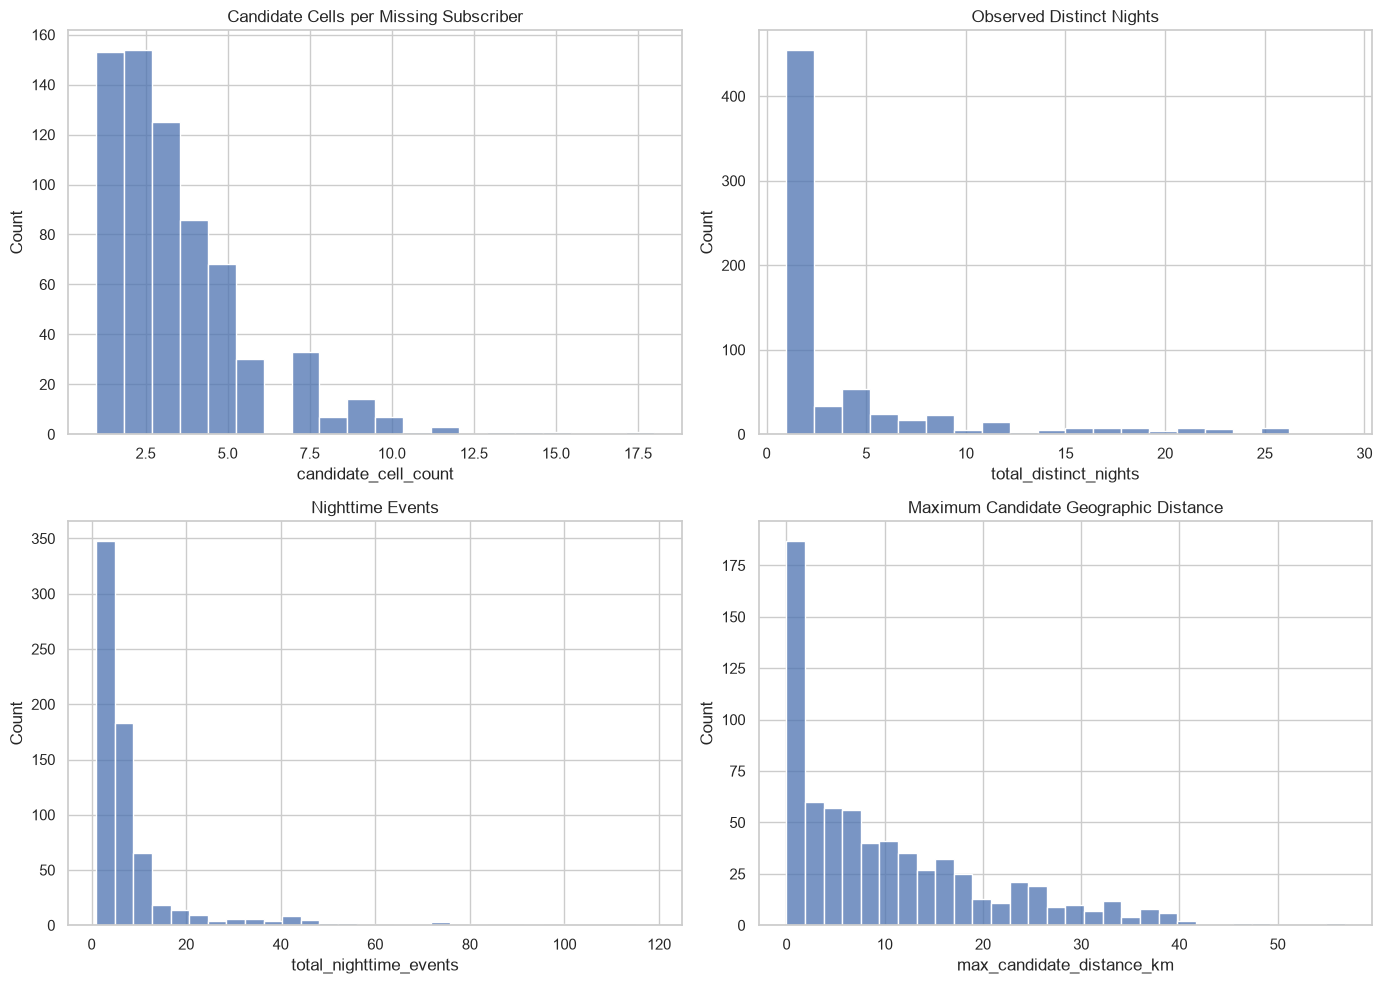

In [327]:
# 53 - Visualise why DBSCAN failed

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    data=missing_subscriber_profile,
    x="candidate_cell_count",
    bins=20,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Candidate Cells per Missing Subscriber")

sns.histplot(
    data=missing_subscriber_profile,
    x="total_distinct_nights",
    bins=20,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Observed Distinct Nights")

sns.histplot(
    data=missing_subscriber_profile,
    x="total_nighttime_events",
    bins=30,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Nighttime Events")

sns.histplot(
    data=missing_subscriber_profile,
    x="max_candidate_distance_km",
    bins=30,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Maximum Candidate Geographic Distance")

plt.tight_layout()
plt.show()

### Interpretation and Summary

The visualisations reveal that DBSCAN struggles primarily because many subscribers have limited nighttime observations and geographically dispersed candidate cells.

- **Candidate cells:** Most subscribers have between 1 and 5 candidate cells, with relatively few having more than 7.
- **Observed distinct nights:** Most subscribers have observations across only 1–3 distinct nights, providing limited evidence of consistent residential behaviour.
- **Nighttime events:** Activity is heavily concentrated at low event counts. Most subscribers have fewer than 10 nighttime events, while a small number have substantially more.
- **Geographic dispersion:** Candidate locations vary considerably, with some subscribers having cells separated by more than 20–40 km.

**Key takeaway:** DBSCAN failures are driven by two main factors: insufficient nighttime observations and geographical dispersion across candidate cells. The limited number of observations makes it difficult to establish reliable residential clusters.

**Recommendation:** Consider a fallback inference strategy that combines geographic clustering with nighttime presence frequency. Subscribers with insufficient observations should retain an insufficient-evidence classification rather than receive potentially unreliable home-location estimates.

In [328]:
# 54 - Summarise failure reasons

failure_summary = (
    failure_diagnostics.groupby("failure_reason")
    .agg(
        subscribers=("msisdn", "nunique"),
        average_candidate_cells=("candidate_count", "mean"),
        average_noise_cells=("noise_count", "mean"),
        average_largest_cluster=("largest_cluster_size", "mean")
    )
    .reset_index()
)

failure_summary["percentage"] = (
    failure_summary["subscribers"]
    / len(dbscan_missing_ids)
    * 100
)

display(failure_summary)

,failure_reason,subscribers,average_candidate_cells,average_noise_cells,average_largest_cluster,percentage
0,all_candidates_classified_as_noise,532,4.0169,4.0169,0.0000,77.6642
1,fewer_candidates_than_min_samples,153,1.0000,1.0000,0.0000,22.3358


### Interpretation and Summary

The results identify two reasons why DBSCAN failed to estimate home locations for the 685 subscribers:

- **All candidates classified as noise (532 subscribers, 77.66%):** These subscribers had an average of approximately 4 candidate cells, but none formed a sufficiently dense geographic cluster under the selected DBSCAN parameters.
- **Fewer candidates than minimum samples (153 subscribers, 22.34%):** These subscribers had only one candidate cell on average, which was insufficient for DBSCAN to form a cluster.

**Key takeaway:** Geographic clustering failure is the dominant problem, accounting for nearly 78% of failures. The remaining 22% result from insufficient candidate cells.

**Recommendation:** Consider testing alternative DBSCAN parameters, particularly `eps` and `min_samples`, alongside a fallback frequency-based or weighted nighttime inference method. However, avoid relaxing clustering thresholds so much that geographically unrelated locations are grouped together.

#### Part B — Test different DBSCAN parameters

Test multiple combinations of:
- eps_km: maximum distance between neighbouring candidate cells for DBSCAN's density calculation.
- min_samples: minimum number of candidate cells needed to form a cluster, including the point itself.
The purpose is to identify the accuracy-versus-coverage trade-off.

In [329]:
# 55 - Create a parameterised DBSCAN function
# This replaces the fixed-parameter version for experimentation. It preserves the same cluster-selection logic: 
# select the cluster with the greatest summed distinct-night presence, then calculate a weighted geographic centroid.
def run_dbscan_for_subscriber(
    subscriber_candidates,
    eps_km=1.0,
    min_samples=2
):

    candidates = subscriber_candidates.copy()

    if len(candidates) < min_samples:
        return None

    coordinates_rad = np.radians(
        candidates[
            ["median_latitude", "median_longitude"]
        ].to_numpy(dtype=float)
    )

    model = DBSCAN(
        eps=eps_km / EARTH_RADIUS_KM,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    candidates["cluster"] = model.fit_predict(
        coordinates_rad
    )

    clustered = candidates[
        candidates["cluster"] != -1
    ].copy()

    if clustered.empty:
        return None

    cluster_summary = (
        clustered.groupby("cluster")
        .agg(
            total_distinct_nights=("distinct_nights", "sum"),
            total_events=("nighttime_events", "sum")
        )
        .reset_index()
        .sort_values(
            ["total_distinct_nights", "total_events"],
            ascending=False
        )
    )

    best_cluster = cluster_summary.iloc[0]["cluster"]

    selected = clustered[
        clustered["cluster"] == best_cluster
    ].copy()

    weights = selected["distinct_nights"].to_numpy(dtype=float)

    if weights.sum() == 0:
        weights = selected["nighttime_events"].to_numpy(dtype=float)

    if weights.sum() == 0:
        return None

    return {
        "home_latitude": np.average(
            selected["median_latitude"],
            weights=weights
        ),
        "home_longitude": np.average(
            selected["median_longitude"],
            weights=weights
        ),
        "cluster_distinct_nights": selected["distinct_nights"].sum(),
        "cluster_events": selected["nighttime_events"].sum(),
        "cluster_cell_count": selected["cell_id"].nunique(),
        "noise_cell_count": int((candidates["cluster"] == -1).sum())
    }

In [330]:
# 56 - Define parameter combinations
# Test eight distance thresholds and four minimum cluster sizes.

eps_values = [
    0.25,
    0.50,
    0.75,
    1.00,
    1.50,
    2.00,
    3.00,
    5.00
]

min_samples_values = [
    2,
    3,
    4,
    5
]

parameter_combinations = [
    (eps, min_samples)
    for eps in eps_values
    for min_samples in min_samples_values
]

print("Number of parameter combinations:", len(parameter_combinations))

display(
    pd.DataFrame(
        parameter_combinations,
        columns=["eps_km", "min_samples"]
    )
)

Number of parameter combinations: 32


,eps_km,min_samples
0,0.2500,2
1,0.2500,3
2,0.2500,4
3,0.2500,5
4,0.5000,2
5,0.5000,3
6,0.5000,4
7,0.5000,5
8,0.7500,2
9,0.7500,3


### Interpretation and Summary

The code defines a DBSCAN hyperparameter search covering **32 parameter combinations**.

- **Epsilon (`eps_km`):** Eight geographic distance thresholds are tested, ranging from 0.25 km to 5 km.
- **Minimum samples (`min_samples`):** Four minimum cluster sizes are tested: 2, 3, 4 and 5.
- **Total combinations:** 8 distance thresholds × 4 minimum cluster sizes = 32 experiments.

**Key takeaway:** This parameter search explores how different geographic neighbourhood sizes and minimum cluster requirements affect DBSCAN's ability to identify residential clusters.

**Recommendation:** Compare the 32 experiments using:
1. Number of subscribers successfully assigned home locations.
2. Percentage of candidate cells classified as noise.
3. Geographic accuracy against synthetic home references.
4. Percentage of estimates within 500 m, 1 km and 2 km.

The objective is to improve inference coverage without sacrificing geographic accuracy.

In [331]:
# 57 - Prepare the evaluation population
# Use subscribers with a Method 1 estimate and a synthetic reference location as the baseline eligible population.
# This gives us a fixed denominator for measuring DBSCAN coverage. 
# Parameter combinations may still produce different estimated subsets, 
# so we will report coverage alongside accuracy.

tuning_population = evaluation_df.dropna(
    subset=[
        "method1_home_latitude",
        "method1_home_longitude",
        "reference_home_latitude",
        "reference_home_longitude"
    ]
).copy()

tuning_subscriber_ids = set(
    tuning_population["msisdn"]
)

print(
    "Baseline eligible subscribers:",
    len(tuning_population)
)

Baseline eligible subscribers: 2758


In [332]:
# 58 - Run the full parameter grid

parameter_results = []
parameter_estimates = {}

candidate_groups = {
    msisdn: group
    for msisdn, group in candidate_features.groupby(
        "msisdn",
        observed=True
    )
}

for eps, min_samples in parameter_combinations:

    estimates = []

    for msisdn in tuning_subscriber_ids:

        group = candidate_groups.get(msisdn)

        if group is None:
            continue

        result = run_dbscan_for_subscriber(
            group,
            eps_km=eps,
            min_samples=min_samples
        )

        if result is not None:
            estimates.append({
                "msisdn": msisdn,
                **result
            })

    estimates_df = pd.DataFrame(
        estimates,
        columns=[
            "msisdn",
            "home_latitude",
            "home_longitude",
            "cluster_distinct_nights",
            "cluster_events",
            "cluster_cell_count",
            "noise_cell_count"
        ]
    )

    parameter_estimates[(eps, min_samples)] = estimates_df

    if estimates_df.empty:
        parameter_results.append({
            "eps_km": eps,
            "min_samples": min_samples,
            "subscribers_estimated": 0,
            "coverage_pct": 0,
            "mean_error_m": np.nan,
            "median_error_m": np.nan,
            "p90_error_m": np.nan,
            "within_500m_pct": np.nan,
            "within_1km_pct": np.nan,
            "within_2km_pct": np.nan
        })
        continue

    evaluation_subset = estimates_df.merge(
        tuning_population[
            [
                "msisdn",
                "reference_home_latitude",
                "reference_home_longitude"
            ]
        ],
        on="msisdn",
        how="inner"
    )

    errors_m = haversine_km(
        evaluation_subset["home_latitude"],
        evaluation_subset["home_longitude"],
        evaluation_subset["reference_home_latitude"],
        evaluation_subset["reference_home_longitude"]
    ) * 1000

    parameter_results.append({
        "eps_km": eps,
        "min_samples": min_samples,
        "subscribers_estimated": len(evaluation_subset),
        "coverage_pct": (
            len(evaluation_subset) / len(tuning_population) * 100
        ),
        "mean_error_m": np.mean(errors_m),
        "median_error_m": np.median(errors_m),
        "p90_error_m": np.percentile(errors_m, 90),
        "within_500m_pct": np.mean(errors_m <= 500) * 100,
        "within_1km_pct": np.mean(errors_m <= 1000) * 100,
        "within_2km_pct": np.mean(errors_m <= 2000) * 100
    })

    print(
        f"Completed eps={eps} km, "
        f"min_samples={min_samples}, "
        f"coverage={len(evaluation_subset) / len(tuning_population) * 100:.1f}%"
    )


dbscan_parameter_results = pd.DataFrame(parameter_results)

display(
    dbscan_parameter_results.sort_values(
        ["within_1km_pct", "coverage_pct"],
        ascending=False
    )
)

Completed eps=0.25 km, min_samples=2, coverage=43.7%
Completed eps=0.25 km, min_samples=3, coverage=19.0%
Completed eps=0.25 km, min_samples=4, coverage=8.7%
Completed eps=0.25 km, min_samples=5, coverage=3.8%
Completed eps=0.5 km, min_samples=2, coverage=60.8%
Completed eps=0.5 km, min_samples=3, coverage=35.3%
Completed eps=0.5 km, min_samples=4, coverage=20.1%
Completed eps=0.5 km, min_samples=5, coverage=10.6%
Completed eps=0.75 km, min_samples=2, coverage=69.9%
Completed eps=0.75 km, min_samples=3, coverage=46.2%
Completed eps=0.75 km, min_samples=4, coverage=29.9%
Completed eps=0.75 km, min_samples=5, coverage=17.9%
Completed eps=1.0 km, min_samples=2, coverage=75.2%
Completed eps=1.0 km, min_samples=3, coverage=54.1%
Completed eps=1.0 km, min_samples=4, coverage=36.6%
Completed eps=1.0 km, min_samples=5, coverage=24.8%
Completed eps=1.5 km, min_samples=2, coverage=81.0%
Completed eps=1.5 km, min_samples=3, coverage=63.3%
Completed eps=1.5 km, min_samples=4, coverage=46.8%
Comple

,eps_km,min_samples,subscribers_estimated,coverage_pct,mean_error_m,median_error_m,p90_error_m,within_500m_pct,within_1km_pct,within_2km_pct
6,0.5000,4,553,20.0508,603.2890,125.1782,"1,552.7324",81.9168,87.1609,91.3201
1,0.2500,3,525,19.0355,641.1837,65.1034,"1,582.3471",81.7143,87.0476,91.2381
2,0.2500,4,240,8.7020,625.8024,59.8842,"2,205.6611",83.7500,86.6667,89.1667
5,0.5000,3,973,35.2792,579.3131,120.6857,"1,429.3591",79.5478,86.2282,93.1141
10,0.7500,4,825,29.9130,644.3153,190.9136,"1,453.6952",76.3636,86.0606,92.1212
14,1.0000,4,1009,36.5845,673.1025,241.7832,"1,367.9532",70.1685,85.9267,92.9633
11,0.7500,5,495,17.9478,695.5576,178.8900,"1,774.5189",76.9697,85.4545,90.5051
7,0.5000,5,293,10.6236,678.3750,144.4237,"2,000.7571",80.5461,85.3242,89.7611
3,0.2500,5,105,3.8071,644.6519,59.1682,"2,193.8673",80.0000,84.7619,88.5714
15,1.0000,5,683,24.7643,745.5197,257.1460,"1,687.6986",67.9356,84.4802,91.0688


### Interpretation and Summary

The 32 DBSCAN experiments reveal a clear trade-off between **residential inference coverage and geographic accuracy**.

- **Coverage increases with epsilon:** Increasing the geographic search radius allows more candidate cells to form clusters, improving subscriber coverage.
- **Minimum samples affects coverage:** Higher `min_samples` requirements generally reduce coverage because more candidate cells must be geographically close together.
- **Best geographic accuracy:** `eps=0.5 km`, `min_samples=4` achieves:
  - 553 subscribers estimated (20.05% coverage).
  - Median error: 125 metres.
  - 87.16% within 1 km.
  - 91.82% within 500 metres.
- **Best higher-coverage alternative:** `eps=0.5 km`, `min_samples=3` achieves:
  - 973 subscribers estimated (35.28% coverage).
  - Median error: 120.69 metres.
  - 86.23% within 1 km.
  - 79.55% within 500 metres.
- **High coverage, lower accuracy:** `eps=5 km`, `min_samples=2` achieves 90.97% coverage, but only 55.08% of estimates fall within 1 km.

**Key takeaway:** Increasing epsilon improves coverage but eventually compromises geographic accuracy. A larger search radius can combine geographically unrelated nighttime locations, producing less reliable residential estimates.

**Recommendation:** Prioritise `eps=0.5 km`, `min_samples=3` as a promising balance between coverage and accuracy. It estimates substantially more subscribers than the highest-accuracy configuration while maintaining strong geographic accuracy.

Further validation should compare these configurations against the existing frequency-based method before selecting the final production approach.

In [333]:
# 59 - Identify the best parameter combinations
# Do not select a parameter combination using mean error alone. Consider accuracy, coverage and the extreme-error tail together.
# For an initial ranking, Use: Within-1-km accuracy, Coverage, 90th-percentile error.

ranked_parameters = dbscan_parameter_results.dropna(
    subset=[
        "within_1km_pct",
        "coverage_pct",
        "p90_error_m"
    ]
).copy()

ranked_parameters = ranked_parameters.sort_values(
    [
        "within_1km_pct",
        "coverage_pct",
        "p90_error_m"
    ],
    ascending=[False, False, True]
)

display(ranked_parameters.head(10))

,eps_km,min_samples,subscribers_estimated,coverage_pct,mean_error_m,median_error_m,p90_error_m,within_500m_pct,within_1km_pct,within_2km_pct
6,0.5000,4,553,20.0508,603.2890,125.1782,"1,552.7324",81.9168,87.1609,91.3201
1,0.2500,3,525,19.0355,641.1837,65.1034,"1,582.3471",81.7143,87.0476,91.2381
2,0.2500,4,240,8.7020,625.8024,59.8842,"2,205.6611",83.7500,86.6667,89.1667
5,0.5000,3,973,35.2792,579.3131,120.6857,"1,429.3591",79.5478,86.2282,93.1141
10,0.7500,4,825,29.9130,644.3153,190.9136,"1,453.6952",76.3636,86.0606,92.1212
14,1.0000,4,1009,36.5845,673.1025,241.7832,"1,367.9532",70.1685,85.9267,92.9633
11,0.7500,5,495,17.9478,695.5576,178.8900,"1,774.5189",76.9697,85.4545,90.5051
7,0.5000,5,293,10.6236,678.3750,144.4237,"2,000.7571",80.5461,85.3242,89.7611
3,0.2500,5,105,3.8071,644.6519,59.1682,"2,193.8673",80.0000,84.7619,88.5714
15,1.0000,5,683,24.7643,745.5197,257.1460,"1,687.6986",67.9356,84.4802,91.0688


### Interpretation and Summary

The ranking identifies the ten strongest DBSCAN parameter configurations based on three criteria: within-1-km accuracy, inference coverage, and 90th-percentile error.

- **Best overall configuration:** `eps=0.5 km`, `min_samples=4`.
  - 553 subscribers estimated (20.05% coverage).
  - 87.16% of estimates within 1 km.
  - 91.32% within 2 km.
  - 90th-percentile error: approximately 1.55 km.

- **Best alternative for higher coverage:** `eps=0.5 km`, `min_samples=3`.
  - 973 subscribers estimated (35.28% coverage).
  - 86.23% within 1 km.
  - 93.11% within 2 km.
  - 90th-percentile error: approximately 1.43 km.

- **General observation:** Smaller epsilon values generally produce more geographically precise clusters but lower subscriber coverage. Increasing epsilon improves coverage but can introduce less accurate residential estimates.

**Key takeaway:** The `0.5 km` configurations dominate the top rankings, suggesting that a relatively tight geographic radius provides a good balance between residential accuracy and coverage.

**Recommendation:** Retain `eps=0.5 km`, `min_samples=4` for higher precision and `eps=0.5 km`, `min_samples=3` as the higher-coverage alternative. Evaluate both against the frequency-based baseline before final selection.

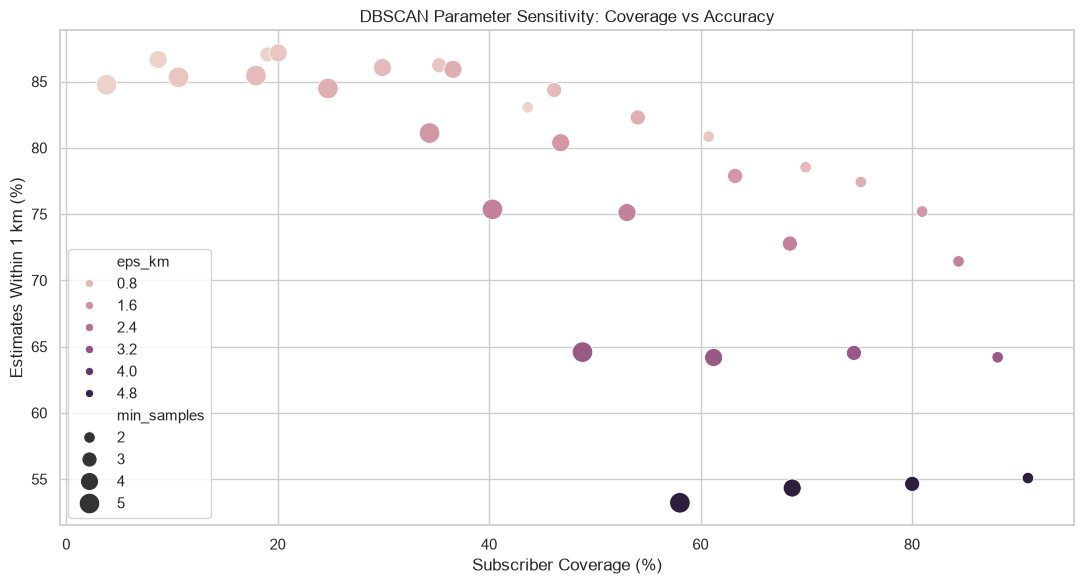

In [334]:
# 60 - Visualise the accuracy and coverage trade-off

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=dbscan_parameter_results,
    x="coverage_pct",
    y="within_1km_pct",
    hue="eps_km",
    size="min_samples",
    sizes=(70, 220)
)

plt.title("DBSCAN Parameter Sensitivity: Coverage vs Accuracy")
plt.xlabel("Subscriber Coverage (%)")
plt.ylabel("Estimates Within 1 km (%)")
plt.tight_layout()
plt.show()

### Interpretation and Summary

The scatter plot illustrates the trade-off between DBSCAN inference coverage and geographic accuracy across different parameter combinations.

- **High accuracy, low coverage:** Smaller epsilon values generally achieve 83–87% accuracy within 1 km but estimate fewer subscribers.
- **Increasing coverage:** Larger epsilon values increase subscriber coverage, sometimes exceeding 90%, but accuracy declines substantially.
- **Effect of minimum samples:** Higher `min_samples` generally reduces coverage because DBSCAN requires more geographically neighbouring candidate cells to form clusters.
- **Best accuracy region:** Configurations with approximately 10–35% coverage achieve around 84–87% accuracy within 1 km.
- **High-coverage region:** Configurations exceeding 80% coverage generally achieve only about 53–75% accuracy within 1 km.

**Key takeaway:** There is a clear inverse relationship between coverage and accuracy. Increasing DBSCAN's geographic radius captures more subscribers but increases the risk of grouping unrelated locations.

**Recommendation:** Prioritise `eps=0.5 km`, `min_samples=3 or 4` as the preferred configurations. They offer a stronger balance between subscriber coverage and geographic accuracy than aggressively increasing epsilon.

The final configuration should depend on whether the business prioritises broader subscriber coverage or more precise residential location estimates.

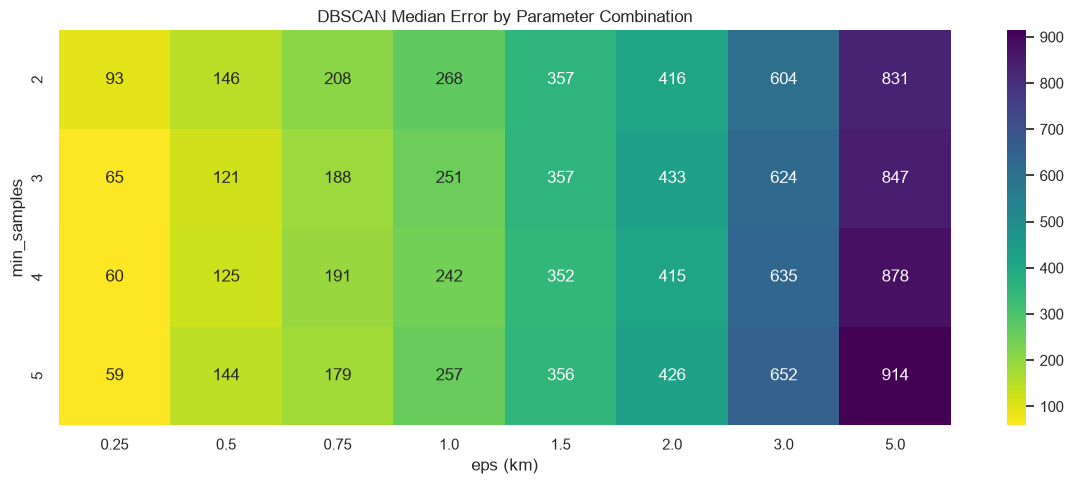

In [335]:
# 61 - Visualise median error by parameters

median_error_pivot = dbscan_parameter_results.pivot(
    index="min_samples",
    columns="eps_km",
    values="median_error_m"
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    median_error_pivot,
    annot=True,
    fmt=".0f",
    cmap="viridis_r"
)

plt.title("DBSCAN Median Error by Parameter Combination")
plt.xlabel("eps (km)")
plt.ylabel("min_samples")
plt.tight_layout()
plt.show()

### Interpretation and Summary

The heatmap shows how DBSCAN's median geographic error changes with different `eps` and `min_samples` combinations.

- **Best accuracy:** Smaller epsilon values produce significantly lower median errors. The best result is `eps=0.25 km`, `min_samples=5`, with a median error of approximately **59 metres**.
- **Effect of epsilon:** Median error increases consistently as epsilon grows, rising from approximately 60–93 metres at 0.25 km to 831–914 metres at 5 km.
- **Effect of min_samples:** Increasing `min_samples` generally improves median accuracy at smaller epsilon values, although the improvement is not consistent across all configurations.
- **Poor configurations:** Larger epsilon values (3–5 km) produce substantially higher median errors, indicating less precise residential location estimates.

**Key takeaway:** Smaller geographic neighbourhoods generally produce more accurate home-location estimates. However, the lowest median error does not necessarily mean the best overall configuration because subscriber coverage also matters.

**Recommendation:** Consider `eps=0.5 km`, `min_samples=4` as a practical configuration, balancing accuracy and coverage. It achieves a median error of approximately **125 metres** while estimating 553 subscribers (20.05% coverage).

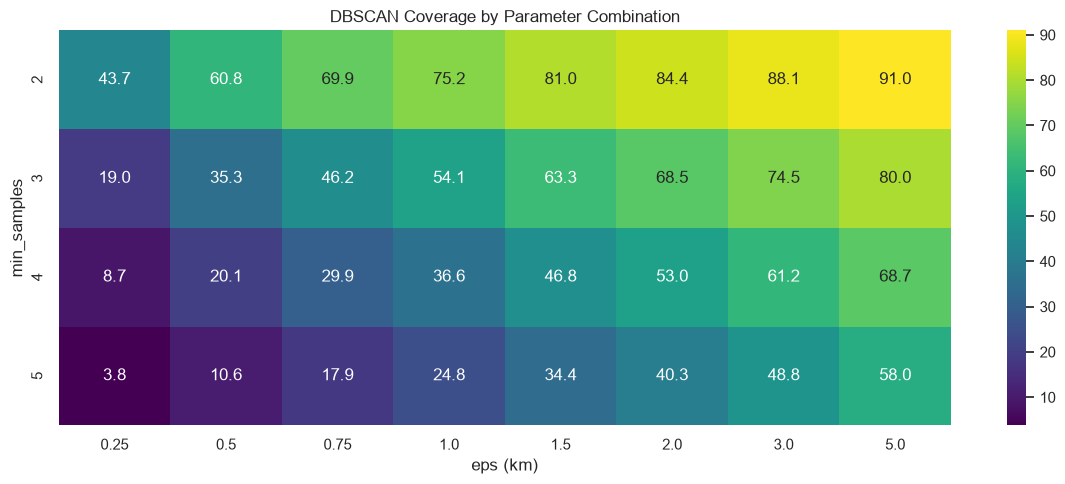

In [336]:
# 62 - Visualise coverage by parameters

coverage_pivot = dbscan_parameter_results.pivot(
    index="min_samples",
    columns="eps_km",
    values="coverage_pct"
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    coverage_pivot,
    annot=True,
    fmt=".1f",
    cmap="viridis"
)

plt.title("DBSCAN Coverage by Parameter Combination")
plt.xlabel("eps (km)")
plt.ylabel("min_samples")
plt.tight_layout()
plt.show()

### Interpretation and Summary

The heatmap illustrates how DBSCAN's subscriber coverage changes with different `eps` and `min_samples` combinations.

- **Effect of epsilon (`eps`):** Increasing the geographic radius consistently improves coverage. For example, with `min_samples=2`, coverage increases from 43.7% at 0.25 km to 91.0% at 5 km.
- **Effect of min_samples:** Increasing the minimum number of points required to form a cluster reduces coverage because more candidate cells must be geographically close together.
- **Highest coverage:** `eps=5.0 km`, `min_samples=2` achieves 91.0% coverage.
- **Lowest coverage:** `eps=0.25 km`, `min_samples=5` achieves only 3.8% coverage.
- **Balanced configuration:** `eps=0.5 km`, `min_samples=4` achieves 20.1% coverage, offering a relatively restrictive geographic clustering threshold.

**Key takeaway:** DBSCAN coverage is highly sensitive to its parameters. Larger epsilon values capture more subscribers but risk combining geographically distant nighttime locations, potentially reducing home-location accuracy.

**Recommendation:** Avoid selecting parameters based on coverage alone. Balance coverage against median distance error, 90th-percentile error and the percentage of estimates within 1 km.

#### Part C — Determine whether the new parameters recover the missing subscribers

In [337]:
# 63 - Measure recovery of the 685 subscribers
# The essence of this is to know which parameter combinations recover subscribers who failed with the original settings (eps=1 km, min_samples=2).

missing_with_reference = (
    set(dbscan_missing_ids)
    .intersection(tuning_subscriber_ids)
)

recovery_results = []

for (eps, min_samples), estimates_df in parameter_estimates.items():

    recovered_ids = set(estimates_df["msisdn"])

    recovered_missing = (
        missing_with_reference.intersection(recovered_ids)
    )

    recovery_results.append({
        "eps_km": eps,
        "min_samples": min_samples,
        "missing_subscribers_recovered": len(recovered_missing),
        "missing_subscribers_remaining": (
            len(missing_with_reference) - len(recovered_missing)
        ),
        "recovery_percentage": (
            len(recovered_missing) / max(len(missing_with_reference), 1) * 100
        )
    })


recovery_summary = pd.DataFrame(recovery_results)

display(
    recovery_summary.sort_values(
        "recovery_percentage",
        ascending=False
    )
)

,eps_km,min_samples,missing_subscribers_recovered,missing_subscribers_remaining,recovery_percentage
28,5.0000,2,436,249,63.6496
24,3.0000,2,357,328,52.1168
20,2.0000,2,255,430,37.2263
29,5.0000,3,241,444,35.1825
16,1.5000,2,160,525,23.3577
25,3.0000,3,154,531,22.4818
30,5.0000,4,121,564,17.6642
21,2.0000,3,80,605,11.6788
31,5.0000,5,62,623,9.0511
26,3.0000,4,49,636,7.1533


### Interpretation and Summary

The results show how different DBSCAN parameter combinations recover the **685 subscribers who failed under the original configuration (`eps=1 km`, `min_samples=2`)**.

- **Best recovery:** `eps=5 km`, `min_samples=2` recovers 436 subscribers (63.65%), leaving 249 unresolved.
- **Second-best:** `eps=3 km`, `min_samples=2` recovers 357 subscribers (52.12%).
- **Moderate recovery:** `eps=2 km`, `min_samples=2` recovers 255 subscribers (37.23%).
- **Effect of min_samples:** Increasing the minimum cluster size significantly reduces recovery. For example, at `eps=5 km`, recovery falls from 436 subscribers with `min_samples=2` to just 62 with `min_samples=5`.
- **No recovery:** Configurations with `eps` between 0.25 km and 1 km recover none of the 685 subscribers.

**Key takeaway:** Recovering subscribers who initially failed DBSCAN requires substantially larger geographic search radii. However, higher recovery does not necessarily mean higher location accuracy.

**Recommendation:** Treat `eps=5 km`, `min_samples=2` as a recovery experiment rather than the default production configuration. Validate the recovered locations against the synthetic reference coordinates before accepting them.

In [338]:
# 64 - Compare original and alternative DBSCAN configurations
# This will help us see whether a larger search radius improves coverage 
# and whether that improvement comes at the cost of accuracy.

# Original configuration
original_result = dbscan_parameter_results[
    (
        dbscan_parameter_results["eps_km"] == 1.0
    )
    & (
        dbscan_parameter_results["min_samples"] == 2
    )
].copy()

# Merge recovery information
parameter_tradeoff = dbscan_parameter_results.merge(
    recovery_summary,
    on=["eps_km", "min_samples"],
    how="left"
)

display(
    parameter_tradeoff.sort_values(
        ["coverage_pct", "within_1km_pct"],
        ascending=False
    )
)

,eps_km,min_samples,subscribers_estimated,coverage_pct,mean_error_m,median_error_m,p90_error_m,within_500m_pct,within_1km_pct,within_2km_pct,missing_subscribers_recovered,missing_subscribers_remaining,recovery_percentage
28,5.0000,2,2509,90.9717,"1,544.9213",830.8382,"3,458.2055",36.5086,55.0817,76.0861,436,249,63.6496
24,3.0000,2,2430,88.1073,"1,294.4656",603.6729,"2,963.1763",45.1029,64.1975,83.1687,357,328,52.1168
20,2.0000,2,2328,84.4090,"1,132.1868",416.2963,"2,751.1945",53.3076,71.4347,86.2973,255,430,37.2263
16,1.5000,2,2233,80.9645,"1,049.3901",356.6327,"2,705.3313",57.9042,75.1903,86.5652,160,525,23.3577
29,5.0000,3,2207,80.0218,"1,462.3482",847.0168,"3,351.1914",35.2515,54.6443,75.8949,241,444,35.1825
12,1.0000,2,2073,75.1632,984.0233,268.3892,"2,711.2039",64.7371,77.4240,86.6860,0,685,0.0000
25,3.0000,3,2055,74.5105,"1,197.7366",624.4503,"2,655.1595",43.9903,64.5255,84.1363,154,531,22.4818
8,0.7500,2,1929,69.9420,918.2768,208.2510,"2,453.1311",69.2068,78.5381,88.0767,0,685,0.0000
30,5.0000,4,1894,68.6730,"1,429.0175",878.0174,"3,244.3211",34.1605,54.3295,76.5048,121,564,17.6642
21,2.0000,3,1888,68.4554,"1,015.6316",433.1068,"2,250.8059",52.9661,72.7754,88.6123,80,605,11.6788


In [339]:
# export the report
parameter_tradeoff.to_csv(
    NOTEBOOK02_OUTPUT / "dbscan_parameter_tradeoff.csv",
    index=False
)

### Interpretation and Summary

The comparison demonstrates that increasing DBSCAN's search radius improves subscriber coverage and recovers previously unclassified subscribers, but generally reduces location accuracy.

- **Original configuration (1 km, min_samples=2):** Provides 75.16% coverage but recovers none of the 685 previously missing subscribers.
- **2 km, min_samples=2:** Recovers 255 previously missing subscribers (37.23%).
- **3 km, min_samples=2:** Recovers 357 subscribers (52.12%).
- **5 km, min_samples=2:** Recovers 436 subscribers (63.65%), leaving only 249 unresolved.
- **Increasing min_samples:** Reduces recovery. At 5 km, increasing `min_samples` from 2 to 3 reduces recovery from 436 to 241 subscribers.

**Key takeaway:** Larger search radii substantially improve coverage and recover subscribers who previously failed DBSCAN. However, this comes with a trade-off in geographic accuracy, as larger radii can group distant nighttime locations together.

**Recommendation:** Retain the original configuration for reliable residential inference and investigate alternative configurations as a separate recovery strategy. Do not automatically accept recovered estimates without validating their geographic accuracy against the reference locations.

In [340]:
# 65 - Inspect the best-performing configuration

if ranked_parameters.empty:
    raise ValueError("No valid DBSCAN parameter combinations were evaluated.")

best_candidate = ranked_parameters.iloc[0]

BEST_EPS_KM = float(best_candidate["eps_km"])
BEST_MIN_SAMPLES = int(best_candidate["min_samples"])

print("Best exploratory DBSCAN configuration:")
print("eps_km:", BEST_EPS_KM)
print("min_samples:", BEST_MIN_SAMPLES)

display(best_candidate.to_frame("value"))

Best exploratory DBSCAN configuration:
eps_km: 0.5
min_samples: 4


,value
eps_km,0.5000
min_samples,4.0000
subscribers_estimated,553.0000
coverage_pct,20.0508
mean_error_m,603.2890
median_error_m,125.1782
p90_error_m,"1,552.7324"
within_500m_pct,81.9168
within_1km_pct,87.1609
within_2km_pct,91.3201


### Interpretation and Summary

The results identify **DBSCAN with `eps=0.5 km` and `min_samples=4`** as the best exploratory configuration based on the combined accuracy and coverage evaluation.

- **Subscribers estimated:** 553, representing 20.05% coverage.
- **Median error:** 125.18 metres, indicating strong typical location accuracy.
- **Mean error:** 603.29 metres, suggesting some estimates have substantially larger errors.
- **Within 500 metres:** 81.92% of estimated locations.
- **Within 1 km:** 87.16% of estimated locations.
- **Within 2 km:** 91.32% of estimated locations.
- **90th percentile error:** 1,552.73 metres, meaning 90% of estimates fall within approximately 1.55 km.

**Key takeaway:** This configuration provides a good balance between geographic accuracy and clustering reliability. Most estimated home locations are within 1 km of their synthetic reference coordinates.

**Recommendation:** Use `eps=0.5 km` and `min_samples=4` as the preferred exploratory configuration. However, its 20.05% coverage means it should not be treated as a complete solution for all subscribers. Further work is needed to improve coverage without compromising accuracy.

In [341]:
# 66 - Compare the original and selected configuration

original_config = dbscan_parameter_results[
    (
        dbscan_parameter_results["eps_km"] == DBSCAN_EPS_KM
    )
    & (
        dbscan_parameter_results["min_samples"] == DBSCAN_MIN_SAMPLES
    )
]

selected_config = dbscan_parameter_results[
    (
        dbscan_parameter_results["eps_km"] == BEST_EPS_KM
    )
    & (
        dbscan_parameter_results["min_samples"] == BEST_MIN_SAMPLES
    )
]

configuration_comparison = pd.concat(
    [
        original_config.assign(configuration="Original"),
        selected_config.assign(configuration="Selected candidate")
    ],
    ignore_index=True
)

display(
    configuration_comparison[
        [
            "configuration",
            "eps_km",
            "min_samples",
            "subscribers_estimated",
            "coverage_pct",
            "mean_error_m",
            "median_error_m",
            "p90_error_m",
            "within_500m_pct",
            "within_1km_pct",
            "within_2km_pct"
        ]
    ]
)

,configuration,eps_km,min_samples,subscribers_estimated,coverage_pct,mean_error_m,median_error_m,p90_error_m,within_500m_pct,within_1km_pct,within_2km_pct
0,Original,1.0000,2,2073,75.1632,984.0233,268.3892,"2,711.2039",64.7371,77.4240,86.6860
1,Selected candidate,0.5000,4,553,20.0508,603.2890,125.1782,"1,552.7324",81.9168,87.1609,91.3201


### Interpretation and Summary

The comparison highlights the trade-off between subscriber coverage and residential location accuracy when moving from the original DBSCAN configuration to the selected candidate.

- **Original configuration (`eps=1 km`, `min_samples=2`):** Estimates 2,073 subscribers (75.16% coverage), with a median error of 268.39 metres and 77.42% of estimates within 1 km.
- **Selected configuration (`eps=0.5 km`, `min_samples=4`):** Estimates 553 subscribers (20.05% coverage), with a lower median error of 125.18 metres and 87.16% within 1 km.
- **Accuracy improvement:** The selected configuration improves the percentage of estimates within 500 metres from 64.74% to 81.92%.
- **Reduced extreme errors:** The 90th-percentile error decreases from 2.71 km to 1.55 km.
- **Coverage trade-off:** The selected configuration estimates 1,520 fewer subscribers than the original configuration.

**Key takeaway:** The selected configuration produces more geographically accurate and reliable residential estimates but sacrifices substantial subscriber coverage.

**Recommendation:** Retain the original configuration when broader subscriber coverage is the priority. Use the selected configuration when residential location accuracy is more important. Consider a tiered inference strategy that uses confidence levels to accommodate both objectives.

In [342]:
# 67 - Inspect the subscribers recovered by the selected configuration

selected_estimates = parameter_estimates[
    (BEST_EPS_KM, BEST_MIN_SAMPLES)
].copy()

selected_subscriber_ids = set(
    selected_estimates["msisdn"]
)

recovered_ids = (
    set(dbscan_missing_ids)
    .intersection(selected_subscriber_ids)
)

still_missing_ids = (
    set(dbscan_missing_ids)
    - selected_subscriber_ids
)

print("Original DBSCAN failures:", len(dbscan_missing_ids))
print("Recovered by selected configuration:", len(recovered_ids))
print("Still without DBSCAN estimates:", len(still_missing_ids))


recovered_subscriber_details = missing_subscriber_profile[
    missing_subscriber_profile["msisdn"].isin(recovered_ids)
].copy()

remaining_subscriber_details = missing_subscriber_profile[
    missing_subscriber_profile["msisdn"].isin(still_missing_ids)
].copy()

print("\nRecovered subscriber profile:")
display(recovered_subscriber_details.head(10))

print("\nRemaining subscriber profile:")
display(remaining_subscriber_details.head(10))

Original DBSCAN failures: 685
Recovered by selected configuration: 0
Still without DBSCAN estimates: 685

Recovered subscriber profile:


,msisdn,candidate_cell_count,total_nighttime_events,total_distinct_nights,observed_nights,mean_candidate_night_presence,max_candidate_night_presence,mean_candidate_event_share,max_candidate_distance_km,failure_reason,noise_count,cluster_count



Remaining subscriber profile:


,msisdn,candidate_cell_count,total_nighttime_events,total_distinct_nights,observed_nights,mean_candidate_night_presence,max_candidate_night_presence,mean_candidate_event_share,max_candidate_distance_km,failure_reason,noise_count,cluster_count
0,subscribers_00200,3,4,2,4,0.3333,0.5000,0.3333,2.0006,all_candidates_classified_as_noise,3,0
1,subscribers_02611,5,20,14,16,0.2250,0.8750,0.2000,8.4338,all_candidates_classified_as_noise,5,0
2,subscribers_02005,2,2,1,2,0.5000,0.5000,0.5000,23.3252,all_candidates_classified_as_noise,2,0
3,subscribers_01726,2,2,1,2,0.5000,0.5000,0.5000,3.9276,all_candidates_classified_as_noise,2,0
4,subscribers_02230,2,3,2,2,0.7500,1.0000,0.5000,3.8475,all_candidates_classified_as_noise,2,0
5,subscribers_02709,2,2,1,2,0.5000,0.5000,0.5000,9.7756,all_candidates_classified_as_noise,2,0
6,subscribers_01749,5,5,1,4,0.2500,0.2500,0.2000,13.6127,all_candidates_classified_as_noise,5,0
7,subscribers_01333,7,8,2,7,0.1633,0.2857,0.1429,25.0286,all_candidates_classified_as_noise,7,0
8,subscribers_02194,1,3,2,2,1.0000,1.0000,1.0000,0.0000,fewer_candidates_than_min_samples,1,0
9,subscribers_00150,7,46,21,24,0.1607,0.8750,0.1429,16.3446,all_candidates_classified_as_noise,7,0


In [343]:
# export the report
remaining_subscriber_details.to_csv(
    NOTEBOOK02_OUTPUT / "remaining_dbscan_subscriber_details.csv",
    index=False
)

### Interpretation and Summary

The results show that the selected DBSCAN configuration (`eps=0.5 km`, `min_samples=4`) fails to recover any of the 685 subscribers who were previously unclassified.

- **Original DBSCAN failures:** 685 subscribers.
- **Recovered subscribers:** 0 (0%).
- **Remaining unresolved:** 685 (100%).

**Why these subscribers remain unresolved:**

Based on the subscriber profile:

- **532 subscribers (77.66%)** had all candidate cells classified as noise, indicating insufficient geographic proximity between their nighttime locations.
- **153 subscribers (22.34%)** had fewer candidate cells than the required minimum of four.
- The median subscriber had only 3 candidate cells and activity across just 1 distinct night.
- Median maximum geographic distance between candidate cells was approximately 6.88 km.

**Key takeaway:** The selected configuration prioritises geographic accuracy over coverage but does not improve recovery of previously failed subscribers. Most failures are caused by geographically dispersed candidate locations or insufficient candidate observations.



#### Home Location Inference — Key Findings and Interpretation
#### Notebook 02: Home Location Inference

### 1. Nighttime Activity as a Basis for Home Location Inference

**Finding: Nighttime mobile network activity provides a useful foundation for identifying potential residential locations, but the consistency of observations matters more than event volume alone.**

The analysis uses nighttime network activity to identify cell towers that subscribers frequently connect to during nighttime hours.

The main features used include:

- `night_events`: Number of nighttime network events recorded at a cell.
- `distinct_nights`: Number of different nights a subscriber appeared at a cell.
- `night_event_share`: Proportion of a subscriber's nighttime events associated with a particular cell.
- `night_presence_ratio`: Proportion of observed nights during which a subscriber appeared at a particular cell.

**Interpretation:**

A subscriber's most frequently visited nighttime cell is a potential residential location, but it is not necessarily their actual home.

For example, a subscriber may generate many events at one location during a single night. Another subscriber may generate fewer events but repeatedly connect to the same cell over several nights.

The second pattern may provide stronger evidence of a habitual residential location.

**Conclusion:** Residential inference should prioritise repeated nighttime presence and temporal consistency rather than relying exclusively on raw event counts.

---

#### 2. Cell Tower Coordinate Validation

**Finding: Approximately 69.54% of cell IDs satisfy the configured 100-metre coordinate consistency threshold, while 30.46% require further investigation.**

| Metric | Result |
|---|---:|
| Total cell IDs analysed | 35,928 |
| Cells passing the consistency threshold | 24,986 |
| Percentage passing | 69.54% |
| Cells requiring review | 10,942 |
| Percentage requiring review | 30.46% |
| Maximum observed coordinate spread | Approximately 61.45 km |

Examples of cell-coordinate inconsistencies include:

- Cell `10000`: approximately 5.99 km coordinate spread.
- Cell `10013`: approximately 18.71 km coordinate spread.
- Cell `10014`: approximately 12.72 km coordinate spread.

**Interpretation:**

The results reveal that most cell IDs have geographically consistent coordinates. However, approximately 30% exhibit coordinate variations exceeding the 100-metre threshold.

Some variations are substantial, with certain cell IDs having coordinates separated by several kilometres.

These inconsistencies can affect residential inference because DBSCAN relies on geographic distances between candidate cell locations.

A cell with incorrect or inconsistent coordinates could introduce artificial geographic movement, distort clustering and reduce the accuracy of inferred home locations.

It is important to note that a cell flagged for review is not necessarily invalid. Coordinate differences may reflect sector-level or network-recording characteristics.

**Conclusion:** Cell-coordinate validation is an important preprocessing requirement. Cells with substantial coordinate variations should be investigated before using their locations for residential inference.

---

#### 3. Nighttime Home-Location Candidate Generation

**Finding: The analysis identified 2,758 subscribers with nighttime candidate locations, generating 24,097 subscriber–cell combinations.**

| Metric | Result |
|---|---:|
| Ordinary subscribers | 2,813 |
| Subscribers with nighttime candidate cells | 2,758 |
| Subscriber–cell candidate combinations | 24,097 |

**Interpretation:**

Each subscriber–cell combination represents a location where a subscriber generated nighttime network activity.

The number of candidate cells varies considerably between subscribers.

For example:

- Some subscribers have only two candidate cells.
- Others have more than ten candidate cells.
- Some subscribers appear across multiple geographic locations during nighttime hours.

This variation is important because a subscriber with many geographically dispersed nighttime locations may be more difficult to classify than someone who repeatedly connects to a small number of neighbouring cells.

The candidate-generation process establishes the geographic search space for the subsequent inference methods.

**Conclusion:** Nighttime candidate generation provides the foundation for residential location inference. Candidate cells should be evaluated using event frequency, distinct nights, repeated presence and geographic consistency.

---

#### 4. Method 1 — Most Frequent Nighttime Cell

**Finding: The event-frequency approach provides a simple baseline for identifying potential residential locations.**

This method selects the cell with the highest number of nighttime events for each subscriber. The number of distinct nights is used as a secondary ranking criterion.

**Interpretation:**

The method is straightforward and easy to interpret.

A cell with a high number of nighttime events may indicate a location where the subscriber regularly spends time.

However, the approach can be influenced by unusually high activity at a particular cell.

For example, a subscriber who generates many events at one cell during a single night may receive a residential estimate that is less reliable than one supported by repeated observations over several nights.

**Conclusion:** The most frequent nighttime cell is a useful baseline, but event frequency alone does not adequately capture the consistency of residential behaviour.

---

#### 5. Method 2 — Most Distinct Nights

**Finding: Prioritising the number of distinct nights provides a more behaviourally meaningful measure of recurring nighttime presence.**

This method selects the cell where the subscriber appeared across the greatest number of distinct nights. Nighttime event frequency is used as a secondary ranking criterion.

**Interpretation:**

Unlike Method 1, this approach prioritises repeated presence rather than the total number of events.

A cell observed across seven different nights provides stronger evidence of recurring nighttime activity than a cell with many events recorded on only one night.

This makes the method less sensitive to unusually high event volumes during individual nights.

However, subscribers with limited observation coverage may still receive weak residential estimates.

**Conclusion:** Distinct-night frequency is an important residential inference feature because it captures temporal consistency rather than simply measuring network activity volume.

---

#### 6. Method 3 — Weighted Nighttime Scoring

**Finding: Combining nighttime presence consistency and event frequency provides a more comprehensive candidate-ranking approach.**

The weighted nighttime score combines:

- `night_presence_ratio`: 70% weight.
- `night_event_share`: 30% weight.

The scoring formula is:

\[
\text{Weighted Score} =
0.7(\text{Night Presence Ratio}) +
0.3(\text{Night Event Share})
\]

**Interpretation:**

The approach gives greater importance to repeated nighttime presence than to raw event frequency.

For example:

| Subscriber | Candidate Cell | Weighted Score |
|---|---:|---:|
| subscribers_00000 | 10235 | 0.667 |
| subscribers_00001 | 23709 | 0.333 |
| subscribers_00002 | 22951 | 0.413 |
| subscribers_00003 | 18804 | 0.839 |
| subscribers_00004 | 20162 | 0.218 |

The cell with the highest weighted score is selected as the potential home location, with distinct nights used as a tie-breaker.

Higher scores indicate stronger relative evidence for a candidate residential location.

However, the weighted score is not a probability that the estimated location is correct.

A high score based on only one or two observed nights may still represent weak evidence.

**Conclusion:** Weighted nighttime scoring combines two complementary behavioural signals and provides a more comprehensive ranking mechanism than raw event frequency alone. However, confidence should also account for the amount of supporting evidence.

---

#### 7. Method 4 — Spatial Clustering Using DBSCAN

**Finding: DBSCAN provides a geographically informed approach to residential inference by grouping nearby nighttime candidate cells.**

DBSCAN uses the Haversine distance metric to identify geographically concentrated groups of candidate cell coordinates.

The process:

1. Collects each subscriber's nighttime candidate cells.
2. Converts cell coordinates into geographic points.
3. Groups geographically neighbouring cells using DBSCAN.
4. Classifies isolated candidate cells as noise.
5. Selects the cluster with the strongest distinct-night support.
6. Calculates a weighted geographic centroid using distinct-night observations as weights.

**Initial results:**

| Metric | Result |
|---|---:|
| Subscribers receiving DBSCAN estimates | 2,073 |
| Ordinary subscribers | 2,813 |
| DBSCAN coverage | 75.16% |
| Subscribers without DBSCAN estimates | 740 |

**Interpretation:**

DBSCAN improves on single-cell selection by recognising that a subscriber may connect to multiple neighbouring cell towers around their residence.

Rather than selecting only one frequently visited cell, the algorithm identifies a geographically concentrated group of candidate locations.

This is particularly useful where neighbouring towers provide overlapping coverage within the same residential area.

However, DBSCAN cannot always identify a qualifying cluster. Subscribers with geographically dispersed nighttime observations or insufficient candidate cells may remain unclassified.

**Conclusion:** DBSCAN introduces valuable geographic information into residential inference and provides a stronger spatial methodology than selecting a single cell based exclusively on nighttime frequency.

---

#### 8. Consolidating the Four Inference Methods

**Finding: The consolidated inference framework generates residential estimates for most ordinary subscribers, although the coverage and supporting evidence vary across methods.**

| Metric | Result |
|---|---:|
| Ordinary subscribers | 2,813 |
| Methods 1, 2 and 3 estimates | 2,758 |
| Method 4 (DBSCAN) estimates | 2,073 |
| Overall estimated status | 2,539 |
| Insufficient evidence | 274 |
| Estimated percentage | 90.26% |
| Insufficient evidence percentage | 9.74% |

**Interpretation:**

The consolidated dataset combines the estimates from all four methods into a single subscriber-level table.

Methods 1, 2 and 3 generate estimates for 2,758 subscribers, while DBSCAN generates estimates for 2,073 subscribers.

The overall inference status classifies 2,539 subscribers as estimated and 274 as having insufficient evidence.

The difference between the DBSCAN coverage and overall inference coverage reflects the fact that the overall status is not determined exclusively by DBSCAN.

**Conclusion:** Combining multiple inference approaches provides a more complete picture of residential location evidence than relying on a single algorithm.

---

#### 9. Initial Confidence Classification

**Finding: Although approximately 90.3% of subscribers receive residential estimates, only 39.5% are classified as high confidence.**

| Confidence category | Subscribers | Percentage |
|---|---:|---:|
| High confidence | 1,112 | 39.53% |
| Medium confidence | 109 | 3.87% |
| Low confidence | 1,318 | 46.85% |
| Insufficient evidence | 274 | 9.74% |
| **Total** | **2,813** | **100%** |

**Interpretation:**

The confidence classification highlights an important distinction between inference coverage and inference reliability.

Although most subscribers receive estimated residential locations, nearly half fall into the low-confidence category.

This suggests that having a predicted home location does not automatically mean there is sufficient evidence to trust the prediction.

High-confidence subscribers have stronger supporting nighttime activity patterns, while low-confidence subscribers have weaker supporting evidence.

The weighted score should be interpreted as a relative candidate score rather than a probability of correctness.

**Conclusion:** Confidence classification is essential for distinguishing strong residential estimates from predictions that require further validation.

---

#### 10. Evaluation Against Synthetic Reference Home Locations

**Finding: Synthetic reference home coordinates were generated for 2,813 subscribers, providing a benchmark for evaluating the inference methods.**

The notebook uses records labelled `home` in the synthetic dataset to calculate a representative reference home coordinate for each subscriber.

The median latitude and longitude of home-labelled observations are used to establish the reference location.

The evaluation uses the Haversine formula to calculate the geographic distance between the inferred home coordinates and the synthetic reference coordinates.

**Important methodological distinction:**

The synthetic reference coordinates are evaluation labels supplied by the data simulator.

They are not independent ground truth obtained from GPS validation, household surveys or field verification.

**Interpretation:**

The reference dataset makes it possible to compare the geographic accuracy of the four inference methods.

However, the number of home-labelled observations varies between subscribers, which may influence the reliability of individual reference coordinates.

The reference coordinates should be used for evaluation rather than fed back into the inference algorithms.

**Conclusion:** The synthetic reference locations provide a useful benchmark for comparing inference approaches, but the results should not be interpreted as independently validated real-world residential accuracy.

---

#### 11. Performance of Method 3 — Weighted Nighttime Scoring

**Finding: Method 3 estimates residential locations for 2,758 subscribers, achieving a median geographic error of approximately 435 metres.**

| Evaluation metric | Result |
|---|---:|
| Subscribers evaluated | 2,758 |
| Mean error | 3,090.89 metres |
| Median error | 434.87 metres |
| 90th percentile error | 9.70 km |
| Within 500 metres | 50.76% |
| Within 1 km | 55.80% |
| Within 2 km | 63.20% |

**Interpretation:**

The median error indicates that half of the estimated residential locations are within approximately 435 metres of their synthetic reference coordinates.

However, the mean error is substantially higher at approximately 3.09 km.

This difference indicates a long-tailed error distribution: many subscribers have relatively accurate estimates, but a smaller group has substantial geographic errors.

The results suggest that weighted nighttime scoring is useful for identifying potential residential locations, but it does not consistently resolve subscribers with multiple or geographically dispersed nighttime locations.

**Conclusion:** Method 3 provides promising estimates for a substantial proportion of subscribers, but outlier predictions and low-confidence estimates require further investigation.

---

#### 12. Comparison of the Four Inference Methods

**Finding: DBSCAN provides the strongest overall geographic accuracy in the notebook's evaluation, although its coverage is lower than the other three methods.**

The notebook compares four approaches:

1. Method 1 — Most Frequent Nighttime Cell.
2. Method 2 — Most Distinct Nights.
3. Method 3 — Weighted Nighttime Scoring.
4. Method 4 — DBSCAN Spatial Clustering.

#### Initial evaluation results

| Metric | Methods 1–3 | DBSCAN |
|---|---:|---:|
| Subscribers evaluated | 2,758 | 2,073 |
| Mean error | Approximately 3.09 km | 984 m |
| Median error | Approximately 435 m | 268 m |
| 90th percentile error | Approximately 9.70 km | 2.71 km |
| Within 500 metres | 50.76% | 64.74% |
| Within 1 km | 55.80% | 77.42% |
| Within 2 km | 63.20% | 86.69% |

**Interpretation:**

DBSCAN outperforms the other three methods across mean error, 90th-percentile error and the percentage of estimates within the selected distance thresholds.

The results suggest that geographically clustering related nighttime cells is more effective than simply selecting the cell with the highest nighttime event frequency or presence ratio.

Methods 1, 2 and 3 perform almost identically, indicating that the additional weighted scoring approach provides limited improvement over the simpler frequency-based methods under the current dataset conditions.

However, DBSCAN estimates fewer subscribers than the other approaches.

This means that its stronger accuracy comes with a coverage limitation.

**Conclusion:** DBSCAN is the strongest overall candidate based on the initial accuracy metrics, but its lower coverage must be considered when selecting the final inference strategy.

---

#### 13. Common-Cohort Evaluation

**Finding: Evaluating all four methods on the same 2,073 subscribers confirms DBSCAN's stronger overall performance, although Method 1 achieves a slightly lower median error.**

The common-cohort evaluation restricts the comparison to subscribers for whom all four methods generated valid estimates.

This ensures that the methods are evaluated against the same subscribers rather than different populations.

#### Key findings

- DBSCAN achieves the lowest mean error at approximately 984 metres.
- The other three methods record mean errors of approximately 2,898 metres.
- DBSCAN achieves a 90th-percentile error of approximately 2.71 km, compared with approximately 9.20 km for the other methods.
- DBSCAN estimates 77.42% of locations within 1 km.
- DBSCAN estimates 86.69% of locations within 2 km.
- Method 1 achieves a slightly lower median error of approximately 223 metres compared with DBSCAN's 268 metres.

**Interpretation:**

The common-cohort evaluation provides a fairer comparison because all methods are tested on the same subscriber population.

Although Method 1 performs slightly better for the median subscriber, DBSCAN performs better across the mean error, upper-tail error and distance-based accuracy thresholds.

This suggests that DBSCAN is more effective at reducing large geographic errors, even though it does not necessarily produce the smallest error for every subscriber.

**Conclusion:** The common-cohort results strengthen the case for DBSCAN as the preferred overall spatial inference method. However, Method 1 remains a useful alternative, particularly where median accuracy and simplicity are important.

---

#### 14. Understanding the 685 Subscribers Who Failed DBSCAN

**Finding: The subsequent DBSCAN failure analysis identifies insufficient geographic clustering and insufficient candidate cells as the two main reasons for unsuccessful inference.**

The notebook profiles 685 subscribers who failed under the original DBSCAN configuration.

#### Subscriber profile

| Metric | Result |
|---|---:|
| Subscribers investigated | 685 |
| Average candidate cells | 3.34 |
| Median candidate cells | 3 |
| Average nighttime events | Approximately 8 |
| Median nighttime events | 4 |
| Average observed nights | 5.75 |
| Median distinct nights | 1 |

**Interpretation:**

The affected subscribers generally have relatively few nighttime candidate locations and limited repeated nighttime observations.

Although some subscribers have substantial nighttime activity, many have activity across only one or two distinct nights.

This makes it difficult to identify a stable residential cluster.

#### Reasons for DBSCAN failure

| Failure reason | Subscribers | Percentage |
|---|---:|---:|
| All candidate cells classified as noise | 532 | 77.66% |
| Insufficient candidate cells | 153 | 22.34% |
| **Total** | **685** | **100%** |

**Interpretation:**

The majority of failures occur because candidate cells do not form a sufficiently dense geographic cluster.

The remaining subscribers have fewer candidate cells than the minimum number required by DBSCAN.

This demonstrates that the problem is not necessarily the complete absence of nighttime activity. Rather, the observations do not provide enough geographically concentrated evidence to establish a reliable residential location.

**Conclusion:** The main limitations of DBSCAN are insufficient geographic concentration and inadequate candidate observations.

---

#### 15. Geographic Dispersion Among Failed Subscribers

**Finding: Geographic dispersion is a major contributor to DBSCAN failure.**

Among the 532 subscribers whose candidate cells were all classified as noise:

| Metric | Result |
|---|---:|
| Average maximum distance between candidate cells | 13.03 km |
| Median maximum distance | 10.12 km |
| Maximum observed distance | 56.81 km |
| Subscribers with candidate cells more than 5 km apart | 405 |
| Percentage with dispersion above 5 km | 76.1% |

**Interpretation:**

Many affected subscribers have nighttime activity across geographically distant cell locations.

For example, a subscriber may connect to one cell several kilometres away from another nighttime candidate cell.

DBSCAN cannot necessarily group these locations into a single residential cluster when the geographic separation exceeds the selected epsilon radius.

The 153 subscribers with insufficient candidate cells must be treated separately. Their zero distance values do not establish that their candidate locations are geographically identical; they indicate insufficient coordinates for calculating dispersion.

**Conclusion:** Geographic dispersion is a significant limitation of nighttime residential inference. A single fixed geographic radius may not work equally well for all subscribers.

---

#### 16. DBSCAN Hyperparameter Tuning

**Finding: DBSCAN performance is highly sensitive to its geographic radius (`eps`) and minimum cluster size (`min_samples`).**

The notebook tests 32 parameter combinations:

- `eps_km`: 0.25, 0.5, 0.75, 1, 1.5, 2, 3 and 5 km.
- `min_samples`: 2, 3, 4 and 5.

The objective is to identify a suitable balance between subscriber coverage and geographic accuracy.

#### General observations

**Effect of epsilon (`eps`):**

Increasing epsilon expands the geographic neighbourhood within which candidate cells can be grouped.

This generally increases the number of subscribers receiving residential estimates, but it also increases the risk of grouping unrelated locations.

**Effect of minimum samples (`min_samples`):**

Increasing `min_samples` makes the clustering requirement more restrictive.

More candidate cells must be geographically close together before a valid cluster can be formed, generally reducing coverage.

**Interpretation:**

The experiments demonstrate a clear inverse relationship between coverage and accuracy.

Smaller geographic radii generally produce more precise residential estimates but leave more subscribers unclassified.

Larger radii improve coverage but can combine geographically distant nighttime locations and reduce prediction accuracy.

**Conclusion:** DBSCAN should not be optimised for coverage alone. Median error, 90th-percentile error and the proportion of estimates within 500 metres, 1 km and 2 km should also inform parameter selection.

---

#### 17. Best DBSCAN Configurations

**Finding: The 0.5 km configurations provide a promising balance between geographic accuracy and subscriber coverage.**

Two configurations stand out in the notebook.

#### Configuration A — Higher precision

`eps=0.5 km`, `min_samples=4`

| Metric | Result |
|---|---:|
| Subscribers estimated | 553 |
| Coverage | 20.05% |
| Mean error | 603.29 m |
| Median error | 125.18 m |
| 90th percentile error | 1,552.73 m |
| Within 500 metres | 81.92% |
| Within 1 km | 87.16% |
| Within 2 km | 91.32% |

#### Configuration B — Higher coverage

`eps=0.5 km`, `min_samples=3`

| Metric | Result |
|---|---:|
| Subscribers estimated | 973 |
| Coverage | 35.28% |
| Median error | 120.69 m |
| Within 500 metres | 79.55% |
| Within 1 km | 86.23% |
| Within 2 km | 93.11% |

**Interpretation:**

Configuration A prioritises stronger geographic accuracy and more restrictive clustering.

Configuration B estimates substantially more subscribers while maintaining relatively strong accuracy.

The difference demonstrates that the optimal configuration depends on the intended application.

If the objective is to minimise geographic errors, Configuration A is attractive.

If the objective is to increase the number of subscribers receiving estimates while maintaining reasonable accuracy, Configuration B is a strong alternative.

**Conclusion:** Retain `eps=0.5 km`, `min_samples=4` as the higher-precision candidate and `eps=0.5 km`, `min_samples=3` as the higher-coverage alternative. Both require further validation before production use.

---

#### 18. Recovering Subscribers Who Failed the Original DBSCAN Configuration

**Finding: Recovering previously unclassified subscribers requires substantially larger geographic search radii, but this comes with an accuracy trade-off.**

The notebook investigates recovery of the 685 subscribers who failed under the original configuration (`eps=1 km`, `min_samples=2`).

#### Recovery results

| Configuration | Subscribers recovered | Recovery percentage |
|---|---:|---:|
| 2 km, min_samples=2 | 255 | 37.23% |
| 3 km, min_samples=2 | 357 | 52.12% |
| 5 km, min_samples=2 | 436 | 63.65% |
| 5 km, min_samples=3 | 241 | 35.18% |
| 5 km, min_samples=4 | 121 | 17.66% |
| 5 km, min_samples=5 | 62 | 9.05% |

**Interpretation:**

The larger geographic radius allows DBSCAN to group candidate cells that were previously classified as noise.

The highest recovery occurs at `eps=5 km`, `min_samples=2`, which recovers 436 of the 685 subscribers.

However, increasing the search radius can group geographically unrelated locations into the same cluster.

Therefore, recovery should not automatically be interpreted as successful or accurate residential inference.

**Conclusion:** Larger epsilon values are useful for investigating previously unclassified subscribers, but recovered locations must be independently evaluated against the synthetic reference coordinates.

---

#### 19. Comparison of Original and Selected DBSCAN Configurations

**Finding: The selected higher-precision configuration improves geographic accuracy but substantially reduces subscriber coverage.**

| Metric | Original: 1 km, min_samples=2 | Selected: 0.5 km, min_samples=4 |
|---|---:|---:|
| Subscribers estimated | 2,073 | 553 |
| Coverage | 75.16% | 20.05% |
| Mean error | 984.02 m | 603.29 m |
| Median error | 268.39 m | 125.18 m |
| 90th percentile error | 2.71 km | 1.55 km |
| Within 500 metres | 64.74% | 81.92% |
| Within 1 km | 77.42% | 87.16% |
| Within 2 km | 86.69% | 91.32% |

**Interpretation:**

The selected configuration improves the percentage of estimates within 500 metres from 64.74% to 81.92%.

It also improves the percentage within 1 km from 77.42% to 87.16%.

The 90th-percentile error falls from approximately 2.71 km to 1.55 km.

However, the selected configuration estimates 1,520 fewer subscribers than the original configuration.

This is a substantial reduction in coverage.

**Conclusion:** The selected configuration is more geographically precise, while the original configuration is more suitable when broader subscriber coverage is the priority. The choice depends on the accuracy requirements of the downstream application.

---

#### 20. Why the Selected Configuration Does Not Recover the Remaining Subscribers

**Finding: The selected configuration (`eps=0.5 km`, `min_samples=4`) does not recover any of the 685 subscribers who failed under the original configuration.**

| Metric | Result |
|---|---:|
| Original DBSCAN failures investigated | 685 |
| Subscribers recovered | 0 |
| Recovery rate | 0% |
| Subscribers remaining unresolved | 685 |

#### Reasons for failure

- **532 subscribers (77.66%):** All candidate cells were classified as noise.
- **153 subscribers (22.34%):** Had fewer candidate cells than the required minimum of four.

The median subscriber had only three candidate cells and nighttime activity across one distinct night.

The median maximum geographic distance between candidate cells was approximately 6.88 km.

**Interpretation:**

The selected configuration is deliberately restrictive because it prioritises geographic accuracy.

Consequently, it does not recover subscribers whose nighttime locations are geographically dispersed or whose candidate observations are insufficient.

The result reinforces the distinction between generating a residential estimate and having sufficient evidence to support that estimate.

**Conclusion:** The 685 unresolved subscribers require a separate fallback strategy. Further tightening DBSCAN parameters is unlikely to address their underlying observation and geographic dispersion problems.

---

#### 21. Overall Findings and Recommendations

The notebook provides several important findings about mobile-network-based residential location inference.

**1. Repeated nighttime presence is valuable**

The number of distinct nights and nighttime presence ratio provide important evidence of habitual residential behaviour.

Raw event volume alone is not sufficient to establish a reliable residential location.

**2. Geographic clustering improves inference accuracy**

DBSCAN generally performs better than single-cell frequency, distinct-night and weighted-score approaches when evaluated against synthetic reference locations.

This suggests that combining neighbouring nighttime cells can produce more geographically accurate estimates.

**3. Coverage and accuracy must be balanced**

The experiments reveal an inverse relationship between subscriber coverage and geographic accuracy.

Larger geographic radii capture more subscribers but increase the risk of combining unrelated locations.

**4. Subscriber confidence remains an important limitation**

Although approximately 90.3% of subscribers receive estimates, only 39.5% are classified as high confidence.

The inference framework should distinguish high-confidence predictions from estimates supported by limited evidence.

**5. Failed DBSCAN predictions require a separate strategy**

The 685 subscribers investigated in the failure analysis generally have sparse nighttime observations or geographically dispersed candidate cells.

A fallback strategy should be developed rather than forcing residential estimates.

#### Recommended next steps

1. Investigate and resolve cell-coordinate inconsistencies before further spatial analysis.
2. Compare the two promising DBSCAN configurations: `eps=0.5 km`, `min_samples=3` and `eps=0.5 km`, `min_samples=4`.
3. Develop a fallback inference method for subscribers who cannot be clustered reliably.
4. Incorporate distinct observed nights, nighttime presence frequency and geographic dispersion into confidence scoring.
5. Evaluate prediction errors separately across high-, medium- and low-confidence subscribers.
6. Validate the final methodology against independent reference locations where possible.
7. Avoid treating low-confidence or insufficient-evidence predictions as confirmed residential locations.

---

#### 22. Final Conclusion

The analysis demonstrates that mobile network data can be used to infer potential subscriber residential locations by examining recurring nighttime activity.

Four inference approaches were developed and evaluated: most frequent nighttime cell, most distinct nights, weighted nighttime scoring and DBSCAN spatial clustering.

Among these approaches, DBSCAN delivers the strongest overall geographic accuracy in the notebook's synthetic evaluation. Its ability to group geographically neighbouring nighttime cells produces more accurate estimates than relying exclusively on event frequency or nighttime presence.

The selected higher-precision configuration (`eps=0.5 km`, `min_samples=4`) estimates 553 subscribers, representing 20.05% coverage, with a median error of approximately 125 metres and 87.16% of estimates within 1 km.

The higher-coverage alternative (`eps=0.5 km`, `min_samples=3`) estimates 973 subscribers, representing 35.28% coverage, while maintaining 86.23% accuracy within 1 km.

However, the analysis also reveals important limitations:

- Approximately 30% of cell IDs require geographic coordinate validation.
- Subscriber nighttime observations vary considerably.
- A significant number of subscribers have geographically dispersed candidate locations.
- DBSCAN does not produce reliable estimates for every subscriber.
- High inference coverage does not automatically translate into high prediction confidence.

**Overall assessment:**

The notebook establishes a promising framework for residential location inference using mobile network activity. DBSCAN is the strongest overall spatial approach evaluated, but a single clustering configuration cannot reliably estimate every subscriber's home location.

The recommended direction is a tiered inference framework that combines spatial clustering, nighttime behavioural scoring and confidence classification. Subscribers should receive residential estimates only when sufficient supporting evidence exists; otherwise, they should retain an insufficient-evidence classification.

Finally, the reported accuracy metrics are based on synthetic reference locations. Independent validation would be required before applying these estimates to real-world population analysis, household targeting or policy decisions.
m